In [1]:
import torch
import pandas as pd
import numpy as np

print("PyTorch:", torch.__version__)
print("GPU disponible:", torch.cuda.is_available())

if torch.cuda.is_available():
    print(torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu130
GPU disponible: True
Tesla T4


In [2]:
!pip install beautifulsoup4 nltk camel-tools sacrebleu

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 23.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 91.4 MB/s  0:00:00
  Created wheel for docopt: filename=docopt-0.6.2-py2.py3-none-any.whl size=13781 sha256=eb21dfde85b8ea43422931ca3f74e8f35582cebc407e3f27f50123f105d0fb01
  Stored in directory: /root/.cache/pip/wheels/0b/1d/03/175286677fb5a1341cc3e4755bf8ec0ed08f3329afd67446b0
Successfully built docopt
  Attempting uninstall: scikit-learnm━━━━━━━━━━━━━━━━━━━━━━━━ 3/8 [portalocker]
    Found existing installation: scikit-learn 1.6.1━━━━━━━━━━━ 3/8 [portalocker]
    Uninstalling scikit-learn-1.6.1:0m━━━━━━━━━━━━━━━━━━━━━━━━ 3/8 [portalocker]
      Successfully uninstalled scikit-learn-1.6.190m━━━━━━━━━━━━━━ 5/8 [scikit-learn]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8/8 [camel-tools] [sacrebleu]rn]


In [3]:

# ==========================================
# 1. IMPORT LIBRARIES
# ==========================================

import os
import re
import time
import requests
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from bs4 import BeautifulSoup

import torch
import torch.nn as nn

from collections import Counter

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("Toutes les bibliothèques ont été importées !")
print("PyTorch version:", torch.__version__)
print("GPU disponible:", torch.cuda.is_available())


Toutes les bibliothèques ont été importées !
PyTorch version: 2.11.0+cu130
GPU disponible: True


In [4]:

# ==========================================
# 2. DEVICE CONFIGURATION
# ==========================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


Device: cuda
GPU: Tesla T4


In [5]:

# ==========================================
# 3. PROJECT CONFIGURATION
# ==========================================

PROJECT_TOPIC = "Artificial Intelligence and Technology"

ARABIC_TOPIC = "الذكاء الاصطناعي والتكنولوجيا"

DATASET_SIZE = 100

OUTPUT_DIR = "/kaggle/working/"

print("Project topic:", PROJECT_TOPIC)
print("Arabic topic:", ARABIC_TOPIC)
print("Target dataset size:", DATASET_SIZE)


Project topic: Artificial Intelligence and Technology
Arabic topic: الذكاء الاصطناعي والتكنولوجيا
Target dataset size: 100


In [6]:

# ==========================================
# 4. WEB SCRAPING FUNCTION
# ==========================================

headers = {
    "User-Agent": "Mozilla/5.0 (compatible; AcademicResearch/1.0)"
}

def scrape_article(url):

    try:
        response = requests.get(
            url,
            headers=headers,
            timeout=20
        )

        response.raise_for_status()

        soup = BeautifulSoup(
            response.text,
            "html.parser"
        )

        # Extract article title
        title_tag = soup.find("h1")

        title = (
            title_tag.get_text(strip=True)
            if title_tag else ""
        )

        # Find article content
        article = soup.find("article")

        if article is None:
            article = soup

        paragraphs = article.find_all("p")

        content = " ".join(
            p.get_text(" ", strip=True)
            for p in paragraphs
        )

        # Basic cleaning
        content = re.sub(r"\s+", " ", content)

        if len(content) < 200:
            print("Article content too short:", url)
            return None

        return {
            "Title": title,
            "Text": content,
            "Source_URL": url
        }

    except Exception as e:

        print("Scraping error:", url, e)

        return None


In [7]:

# ==========================================
# 5. TEST SCRAPER
# ==========================================

test_url = "https://www.aljazeera.net/tech/2026/11/2/هل-يجعلنا-الذكاء-الاصطناعي-أغبى"

article = scrape_article(test_url)

if article:

    print("Title:")
    print(article["Title"])

    print("\nArticle content:")
    print(article["Text"][:1000])

    print("\nText length:", len(article["Text"]))


Title:
هل يجعلنا الذكاء الاصطناعي أغبى؟

Article content:
وقت القراءة: 11 دقيقة استمع تستطيع أدوات الذكاء الاصطناعي اليوم كتابة النصوص، وتلخيص الكتب، وشرح المسائل المعقدة، واقتراح الحلول خلال ثوان، ومع انتقالها إلى تفاصيل العمل والتعليم والحياة اليومية، لم يعد التحدي مقتصرا على دقة الإجابات التي تنتجها، بل امتد إلى دور الإنسان نفسه في الوصول إلى المعرفة، فماذا يحدث لعقولنا عندما تتولى الآلات مهام اعتدنا أن نتعلم من خلالها البحث والتحليل والاستنتاج؟ لا توجد أدلة علمية كافية للقول إن الذكاء الاصطناعي يجعل البشر أقل ذكاء بالضرورة، لكن الأبحاث تطرح سؤالا أكثر دقة: هل يمكن أن يؤدي الاعتماد عليه إلى تقليص الممارسة الذهنية التي يحتاج إليها الإنسان كي يتعلم ويتذكر ويفكر بصورة مستقلة؟ هنا تكمن المسألة الأساسية، فالأداة التي توفر الوقت قد توسع قدراتنا، لكنها قد تحرمنا أيضا من بعض فرص التعلم إذا استخدمناها بديلا عن التفكير، لا وسيلة لدعمه. في السابق، كان الوصول إلى إجابة يتطلب غالبا تحديد السؤال، والبحث بين مصادر متعددة، ومقارنة المعلومات، ثم بناء استنتاج يمكن مراجعته، أما أدوات الذكاء الاصطناعي 

In [8]:

# ==========================================
# 6. COLLECT MULTIPLE ARTICLES
# ==========================================

article_urls = [

     # Al Jazeera
    "https://www.aljazeera.net/tech/2026/7/22/الذكاء-الاصطناعي-باللغة-العربية-هل",

    "https://www.aljazeera.net/tech/2026/11/2/هل-يجعلنا-الذكاء-الاصطناعي-أغبى",

    # BBC Arabic
    "https://bbc.com/arabic/science-and-tech-65227031",

    "https://jadidan.news/ar/article/166683/",

    # Sky News Arabia
    "https://www.skynewsarabia.com/amp/blog/1666312-الذكاء-الاصطناعي-يجلب-فرصا-جديدة-وايضا-مخاطر-جديدة",

    "https://www.skynewsarabia.com/amp/business/1681968-هي-تطبيقات-الذكاء-الاصطناعي-استخداما"

]

articles = []

for url in article_urls:

    result = scrape_article(url)

    if result is not None:
        articles.append(result)

    time.sleep(2)

raw_df = pd.DataFrame(articles)

print("Number of collected articles:", len(raw_df))

display(raw_df.head())


Number of collected articles: 6


,Title,Text,Source_URL
0,الذكاء الاصطناعي باللغة العربية.. هل اقتربنا م...,وقت القراءة: 6 دقائق الذكاء الاصطناعي باللغة ا...,https://www.aljazeera.net/tech/2026/7/22/الذكا...
1,هل يجعلنا الذكاء الاصطناعي أغبى؟,وقت القراءة: 11 دقيقة استمع تستطيع أدوات الذكا...,https://www.aljazeera.net/tech/2026/11/2/هل-يج...
2,الذكاء الاصطناعي: هل تهدّد هذه التكنولوجيا مست...,صدر الصورة، Getty Images ربما قرأت في السنوات ...,https://bbc.com/arabic/science-and-tech-65227031
3,مواد جديدة يصممها الذكاء الاصطناعي قد تغير مست...,BBC 16 نوفمبر 2026 بقلم BBC News عربي مواد جدي...,https://jadidan.news/ar/article/166683/
4,الذكاء الاصطناعي يجلب فرصا جديدة.. وأيضا مخاطر...,*مقال بقلم رئيس الوزراء البريطاني ريشي سوناك أ...,https://www.skynewsarabia.com/amp/blog/1666312...


In [9]:

# ==========================================
# 7. SAVE RAW DATASET
# ==========================================

raw_df.to_csv(
    OUTPUT_DIR + "arabic_raw_dataset.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Dataset saved successfully!")

print("Dataset shape:", raw_df.shape)


Dataset saved successfully!
Dataset shape: (6, 3)


In [10]:

# ==========================================
# 8. ADD RELEVANCE SCORES
# ==========================================

raw_df["Score"] = np.nan

display(
    raw_df[["Title", "Text", "Score"]].head(10)
)


,Title,Text,Score
0,الذكاء الاصطناعي باللغة العربية.. هل اقتربنا م...,وقت القراءة: 6 دقائق الذكاء الاصطناعي باللغة ا...,NaN
1,هل يجعلنا الذكاء الاصطناعي أغبى؟,وقت القراءة: 11 دقيقة استمع تستطيع أدوات الذكا...,NaN
2,الذكاء الاصطناعي: هل تهدّد هذه التكنولوجيا مست...,صدر الصورة، Getty Images ربما قرأت في السنوات ...,NaN
3,مواد جديدة يصممها الذكاء الاصطناعي قد تغير مست...,BBC 16 نوفمبر 2026 بقلم BBC News عربي مواد جدي...,NaN
4,الذكاء الاصطناعي يجلب فرصا جديدة.. وأيضا مخاطر...,*مقال بقلم رئيس الوزراء البريطاني ريشي سوناك أ...,NaN
5,We apologize for the inconvenience...,...but your activity and behavior on this site...,NaN


In [11]:
for i, row in raw_df.iterrows():
    print(f"\nArticle {i}")
    print("Titre :", row["Title"])
    print("Extrait :", row["Text"][:500])
    print("-" * 80)


Article 0
Titre : الذكاء الاصطناعي باللغة العربية.. هل اقتربنا من نماذج تفهم لهجات المنطقة؟
Extrait : وقت القراءة: 6 دقائق الذكاء الاصطناعي باللغة العربية يشهد تطورا متسارعا مع ظهور نماذج متخصصة تهدف إلى فهم اللغة وسياقاتها الثقافية (الجزيرة) استمع كانت اللغة العربية في عالم الذكاء الاصطناعي تعتبر مجرد لغة تُترجم إليها الإجابات أو تُدعم في واجهات الاستخدام، لكن حاليا أصبحت محور سباق تقني متسارع تقوده شركات عالمية ومؤسسات بحثية عربية لتطوير نماذج لغوية قادرة على فهم خصوصية العربية ولهجاتها المتعددة. وخلال العامين الأخيرين، انتقل التركيز من دعم العربية الفصحى إلى معالجة تحدٍ أكثر تعقيدا، يتمثل في 
--------------------------------------------------------------------------------

Article 1
Titre : هل يجعلنا الذكاء الاصطناعي أغبى؟
Extrait : وقت القراءة: 11 دقيقة استمع تستطيع أدوات الذكاء الاصطناعي اليوم كتابة النصوص، وتلخيص الكتب، وشرح المسائل المعقدة، واقتراح الحلول خلال ثوان، ومع انتقالها إلى تفاصيل العمل والتعليم والحياة اليومية، لم يعد التحدي مقتصرا على دقة الإجابات التي تنتجها، بل امت

In [12]:
# ==========================================
# 8. ADD RELEVANCE SCORES
# ==========================================

scores = [10, 9, 9, 10, 0, 0]

# Vérifier que le nombre de scores correspond
# au nombre d'articles
assert len(scores) == len(raw_df)

# Ajouter les scores
raw_df["Score"] = scores

# Afficher les résultats
display(raw_df[["Title", "Score"]])

# Sauvegarder le dataset
raw_df.to_csv(
    "/kaggle/working/arabic_dataset.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Dataset saved successfully!")

,Title,Score
0,الذكاء الاصطناعي باللغة العربية.. هل اقتربنا م...,10
1,هل يجعلنا الذكاء الاصطناعي أغبى؟,9
2,الذكاء الاصطناعي: هل تهدّد هذه التكنولوجيا مست...,9
3,مواد جديدة يصممها الذكاء الاصطناعي قد تغير مست...,10
4,الذكاء الاصطناعي يجلب فرصا جديدة.. وأيضا مخاطر...,0
5,We apologize for the inconvenience...,0


Dataset saved successfully!


In [13]:
# ==========================================
# 2.1. PREPARE THE DATASET
# ==========================================

# Supprimer les lignes sans texte
raw_df = raw_df.dropna(subset=["Text", "Score"])

# Supprimer les textes trop courts ou les pages d'erreur
raw_df = raw_df[
    raw_df["Text"].str.len() > 200
].copy()

# Réinitialiser les index
raw_df = raw_df.reset_index(drop=True)

print("Nombre d'articles exploitables :", len(raw_df))

display(raw_df[["Title", "Score"]])

Nombre d'articles exploitables : 6


,Title,Score
0,الذكاء الاصطناعي باللغة العربية.. هل اقتربنا م...,10
1,هل يجعلنا الذكاء الاصطناعي أغبى؟,9
2,الذكاء الاصطناعي: هل تهدّد هذه التكنولوجيا مست...,9
3,مواد جديدة يصممها الذكاء الاصطناعي قد تغير مست...,10
4,الذكاء الاصطناعي يجلب فرصا جديدة.. وأيضا مخاطر...,0
5,We apologize for the inconvenience...,0


In [14]:
import re
import pandas as pd
import numpy as np

from camel_tools.utils.dediac import dediac_ar
from camel_tools.tokenizers.word import simple_word_tokenize

from nltk.corpus import stopwords
from nltk.stem.isri import ISRIStemmer

import nltk

nltk.download("stopwords")

[nltk_data] Downloading package stopwords to /usr/share/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [15]:
# ==========================================
# ARABIC TEXT NORMALIZATION
# ==========================================

def normalize_arabic(text):

    # Convertir en minuscules
    text = text.lower()

    # Supprimer les signes diacritiques
    text = dediac_ar(text)

    # Supprimer le Tatweel
    text = text.replace("ـ", "")

    # Uniformiser certaines lettres arabes
    text = re.sub("[إأآٱ]", "ا", text)
    text = re.sub("ى", "ي", text)
    text = re.sub("ؤ", "و", text)
    text = re.sub("ئ", "ي", text)

    # Garder uniquement les lettres arabes et les espaces
    text = re.sub(r"[^\u0600-\u06FF\s]", " ", text)

    # Supprimer les espaces multiples
    text = re.sub(r"\s+", " ", text).strip()

    return text

In [16]:
# ==========================================
# TOKENIZATION
# ==========================================

raw_df["Normalized_Text"] = raw_df["Text"].apply(
    normalize_arabic
)

raw_df["Tokens"] = raw_df["Normalized_Text"].apply(
    simple_word_tokenize
)

display(
    raw_df[["Title", "Tokens"]].head()
)

,Title,Tokens
0,الذكاء الاصطناعي باللغة العربية.. هل اقتربنا م...,"[وقت, القراءة, دقايق, الذكاء, الاصطناعي, باللغ..."
1,هل يجعلنا الذكاء الاصطناعي أغبى؟,"[وقت, القراءة, دقيقة, استمع, تستطيع, ادوات, ال..."
2,الذكاء الاصطناعي: هل تهدّد هذه التكنولوجيا مست...,"[صدر, الصورة, ،, ربما, قرات, في, السنوات, القل..."
3,مواد جديدة يصممها الذكاء الاصطناعي قد تغير مست...,"[نوفمبر, بقلم, عربي, مواد, جديدة, يصممها, الذك..."
4,الذكاء الاصطناعي يجلب فرصا جديدة.. وأيضا مخاطر...,"[مقال, بقلم, رييس, الوزراء, البريطاني, ريشي, س..."


In [17]:
# ==========================================
# REMOVE STOP WORDS
# ==========================================

arabic_stopwords = set(stopwords.words("arabic"))

def remove_stopwords(tokens):

    return [
        word for word in tokens
        if word not in arabic_stopwords
    ]

raw_df["Tokens_No_Stopwords"] = raw_df["Tokens"].apply(
    remove_stopwords
)

display(
    raw_df[["Tokens", "Tokens_No_Stopwords"]].head()
)

,Tokens,Tokens_No_Stopwords
0,"[وقت, القراءة, دقايق, الذكاء, الاصطناعي, باللغ...","[وقت, القراءة, دقايق, الذكاء, الاصطناعي, باللغ..."
1,"[وقت, القراءة, دقيقة, استمع, تستطيع, ادوات, ال...","[وقت, القراءة, دقيقة, استمع, تستطيع, ادوات, ال..."
2,"[صدر, الصورة, ،, ربما, قرات, في, السنوات, القل...","[صدر, الصورة, ،, ربما, قرات, السنوات, القليلة,..."
3,"[نوفمبر, بقلم, عربي, مواد, جديدة, يصممها, الذك...","[بقلم, عربي, مواد, جديدة, يصممها, الذكاء, الاص..."
4,"[مقال, بقلم, رييس, الوزراء, البريطاني, ريشي, س...","[مقال, بقلم, رييس, الوزراء, البريطاني, ريشي, س..."


In [18]:
# ==========================================
# ARABIC STEMMING
# ==========================================

stemmer = ISRIStemmer()

def apply_stemming(tokens):

    return [
        stemmer.stem(word)
        for word in tokens
    ]

raw_df["Stemmed_Tokens"] = raw_df[
    "Tokens_No_Stopwords"
].apply(apply_stemming)

display(
    raw_df[["Tokens_No_Stopwords", "Stemmed_Tokens"]].head()
)

,Tokens_No_Stopwords,Stemmed_Tokens
0,"[وقت, القراءة, دقايق, الذكاء, الاصطناعي, باللغ...","[وقت, قرء, دقيق, ذكء, صطناع, لغة, عرب, شهد, تط..."
1,"[وقت, القراءة, دقيقة, استمع, تستطيع, ادوات, ال...","[وقت, قرء, دقق, سمع, تطع, ادو, ذكء, صطناع, الي..."
2,"[صدر, الصورة, ،, ربما, قرات, السنوات, القليلة,...","[صدر, صور, ،, ربم, قرت, سنو, قلل, اضة, ،, حلل,..."
3,"[بقلم, عربي, مواد, جديدة, يصممها, الذكاء, الاص...","[قلم, عرب, واد, جدد, صمم, ذكء, صطناع, تغر, قبل..."
4,"[مقال, بقلم, رييس, الوزراء, البريطاني, ريشي, س...","[قال, قلم, ريس, زرء, برط, ريش, سون, عقد, انه, ..."


In [19]:
# ==========================================
# SCORE DISCRETIZATION
# ==========================================

def discretize_score(score):

    if score <= 3:
        return 0
    elif score <= 6:
        return 1
    else:
        return 2

raw_df["Label"] = raw_df["Score"].apply(
    discretize_score
)

# Afficher les scores et leurs classes
display(
    raw_df[["Title", "Score", "Label"]]
)

print("\nDistribution des classes :")
print(raw_df["Label"].value_counts())

,Title,Score,Label
0,الذكاء الاصطناعي باللغة العربية.. هل اقتربنا م...,10,2
1,هل يجعلنا الذكاء الاصطناعي أغبى؟,9,2
2,الذكاء الاصطناعي: هل تهدّد هذه التكنولوجيا مست...,9,2
3,مواد جديدة يصممها الذكاء الاصطناعي قد تغير مست...,10,2
4,الذكاء الاصطناعي يجلب فرصا جديدة.. وأيضا مخاطر...,0,0
5,We apologize for the inconvenience...,0,0



Distribution des classes :
Label
2    4
0    2
Name: count, dtype: int64


In [20]:
# ==========================================
# BUILD VOCABULARY
# ==========================================

from collections import Counter

all_tokens = []

for tokens in raw_df["Tokens_No_Stopwords"]:
    all_tokens.extend(tokens)

word_counts = Counter(all_tokens)

# 0 = padding, 1 = mot inconnu
vocab = {
    "<PAD>": 0,
    "<UNK>": 1
}

for word in word_counts:
    vocab[word] = len(vocab)

print("Taille du vocabulaire :", len(vocab))

Taille du vocabulaire : 1840


In [21]:
# ==========================================
# TEXT TO NUMERICAL SEQUENCES
# ==========================================

MAX_LEN = 300

def encode_text(tokens):

    sequence = [
        vocab.get(word, vocab["<UNK>"])
        for word in tokens
    ]

    # Tronquer les séquences trop longues
    sequence = sequence[:MAX_LEN]

    # Ajouter du padding
    sequence += [vocab["<PAD>"]] * (
        MAX_LEN - len(sequence)
    )

    return sequence

X = np.array([
    encode_text(tokens)
    for tokens in raw_df["Tokens_No_Stopwords"]
])

y = raw_df["Label"].values

print("Shape de X :", X.shape)
print("Shape de y :", y.shape)

Shape de X : (6, 300)
Shape de y : (6,)


In [22]:
# ==========================================
# IMPORT PYTORCH
# ==========================================

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import TensorDataset, DataLoader

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

Device: cuda


In [23]:
# ==========================================
# CHECK CLASS DISTRIBUTION
# ==========================================

unique_classes = np.unique(y)

print("Classes présentes :", unique_classes)
print("Nombre de classes :", len(unique_classes))

if len(unique_classes) < 2:
    print("Attention : une seule classe est présente.")
    print("L'entraînement d'un classificateur pertinent")
    print("n'est pas possible avec ce dataset.")
else:
    print("Le dataset contient plusieurs classes.")

Classes présentes : [0 2]
Nombre de classes : 2
Le dataset contient plusieurs classes.


In [24]:
# ==========================================
# DEEP LEARNING MODELS
# ==========================================

class ArabicTextClassifier(nn.Module):

    def __init__(
        self,
        vocab_size,
        embedding_dim=64,
        hidden_dim=64,
        num_classes=3,
        model_type="RNN"
    ):

        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            embedding_dim,
            padding_idx=0
        )

        if model_type == "RNN":

            self.recurrent = nn.RNN(
                embedding_dim,
                hidden_dim,
                batch_first=True
            )

            directions = 1

        elif model_type == "BiRNN":

            self.recurrent = nn.RNN(
                embedding_dim,
                hidden_dim,
                batch_first=True,
                bidirectional=True
            )

            directions = 2

        elif model_type == "GRU":

            self.recurrent = nn.GRU(
                embedding_dim,
                hidden_dim,
                batch_first=True
            )

            directions = 1

        elif model_type == "LSTM":

            self.recurrent = nn.LSTM(
                embedding_dim,
                hidden_dim,
                batch_first=True
            )

            directions = 1

        else:
            raise ValueError("Unknown model type")

        self.fc = nn.Linear(
            hidden_dim * directions,
            num_classes
        )

    def forward(self, x):

        embedded = self.embedding(x)

        output = self.recurrent(embedded)

        if isinstance(output, tuple):
            hidden = output[1]

            if isinstance(hidden, tuple):
                hidden = hidden[0]

            hidden = hidden[-1]

        else:
            hidden = output[0][:, -1, :]

        return self.fc(hidden)

In [25]:
# ==========================================
# INITIALIZE FOUR MODELS
# ==========================================

model_types = ["RNN", "BiRNN", "GRU", "LSTM"]

models = {}

for model_type in model_types:

    model = ArabicTextClassifier(
        vocab_size=len(vocab),
        embedding_dim=64,
        hidden_dim=64,
        num_classes=3,
        model_type=model_type
    ).to(device)

    models[model_type] = model

    print(model_type, "initialized successfully")

RNN initialized successfully
BiRNN initialized successfully
GRU initialized successfully
LSTM initialized successfully


In [26]:
# ==========================================
# MODEL EVALUATION
# ==========================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

def evaluate_model(y_true, y_pred):

    print("Accuracy:",
          accuracy_score(y_true, y_pred))

    print("Precision:",
          precision_score(
              y_true, y_pred,
              average="macro",
              zero_division=0
          ))

    print("Recall:",
          recall_score(
              y_true, y_pred,
              average="macro",
              zero_division=0
          ))

    print("F1-score:",
          f1_score(
              y_true, y_pred,
              average="macro",
              zero_division=0
          ))

    print("\nClassification Report:")
    print(classification_report(
        y_true, y_pred,
        zero_division=0
    ))

    print("Confusion Matrix:")
    print(confusion_matrix(y_true, y_pred))

In [27]:
class ArabicTextClassifier(nn.Module):

    def __init__(self, vocab_size, embedding_dim=64,
                 hidden_dim=64, num_classes=3,
                 model_type="RNN"):

        super().__init__()

        self.model_type = model_type

        self.embedding = nn.Embedding(
            vocab_size, embedding_dim, padding_idx=0
        )

        if model_type in ["RNN", "BiRNN"]:
            self.recurrent = nn.RNN(
                embedding_dim, hidden_dim,
                batch_first=True,
                bidirectional=(model_type == "BiRNN")
            )
            directions = 2 if model_type == "BiRNN" else 1

        elif model_type == "GRU":
            self.recurrent = nn.GRU(
                embedding_dim, hidden_dim,
                batch_first=True
            )
            directions = 1

        elif model_type == "LSTM":
            self.recurrent = nn.LSTM(
                embedding_dim, hidden_dim,
                batch_first=True
            )
            directions = 1

        self.fc = nn.Linear(
            hidden_dim * directions, num_classes
        )

    def forward(self, x):

        embedded = self.embedding(x)
        output, hidden = self.recurrent(embedded)

        if self.model_type == "BiRNN":
            hidden = hidden.reshape(2, x.size(0), -1)
            representation = torch.cat(
                (hidden[-2], hidden[-1]), dim=1
            )

        elif self.model_type == "LSTM":
            hidden = hidden[0]
            representation = hidden[-1]

        else:
            representation = hidden[-1]

        return self.fc(representation)

In [28]:
# ==========================================
# TRAINING FOUR MODELS
# ==========================================

X_tensor = torch.tensor(X, dtype=torch.long)
y_tensor = torch.tensor(y, dtype=torch.long)

dataset = TensorDataset(X_tensor, y_tensor)

loader = DataLoader(
    dataset,
    batch_size=2,
    shuffle=True
)

results = {}

for model_type in ["RNN", "BiRNN", "GRU", "LSTM"]:

    print("\nTraining:", model_type)

    model = ArabicTextClassifier(
        vocab_size=len(vocab),
        embedding_dim=64,
        hidden_dim=64,
        num_classes=3,
        model_type=model_type
    ).to(device)

    criterion = nn.CrossEntropyLoss()

    optimizer = optim.Adam(
        model.parameters(),
        lr=0.001
    )

    for epoch in range(10):

        model.train()
        total_loss = 0

        for batch_X, batch_y in loader:

            batch_X = batch_X.to(device)
            batch_y = batch_y.to(device)

            optimizer.zero_grad()

            outputs = model(batch_X)
            loss = criterion(outputs, batch_y)

            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        print(
            f"Epoch {epoch+1}/10 - "
            f"Loss: {total_loss / len(loader):.4f}"
        )

    results[model_type] = model

print("\nTraining completed!")


Training: RNN
Epoch 1/10 - Loss: 1.0839
Epoch 2/10 - Loss: 0.8909
Epoch 3/10 - Loss: 0.7447
Epoch 4/10 - Loss: 0.6405
Epoch 5/10 - Loss: 0.5660
Epoch 6/10 - Loss: 0.5001
Epoch 7/10 - Loss: 0.4549
Epoch 8/10 - Loss: 0.4264
Epoch 9/10 - Loss: 0.4050
Epoch 10/10 - Loss: 0.3851

Training: BiRNN
Epoch 1/10 - Loss: 1.1462
Epoch 2/10 - Loss: 0.7470
Epoch 3/10 - Loss: 0.5778
Epoch 4/10 - Loss: 0.4315
Epoch 5/10 - Loss: 0.3310
Epoch 6/10 - Loss: 0.2761
Epoch 7/10 - Loss: 0.2409
Epoch 8/10 - Loss: 0.2135
Epoch 9/10 - Loss: 0.1958
Epoch 10/10 - Loss: 0.1720

Training: GRU
Epoch 1/10 - Loss: 1.1550
Epoch 2/10 - Loss: 1.0341
Epoch 3/10 - Loss: 0.9269
Epoch 4/10 - Loss: 0.8248
Epoch 5/10 - Loss: 0.7484
Epoch 6/10 - Loss: 0.6757
Epoch 7/10 - Loss: 0.6138
Epoch 8/10 - Loss: 0.5608
Epoch 9/10 - Loss: 0.5075
Epoch 10/10 - Loss: 0.4626

Training: LSTM
Epoch 1/10 - Loss: 1.1684
Epoch 2/10 - Loss: 1.0988
Epoch 3/10 - Loss: 1.0410
Epoch 4/10 - Loss: 0.9782
Epoch 5/10 - Loss: 0.9283
Epoch 6/10 - Loss: 0.881

In [29]:
print("Nombre d'articles :", len(y))
print("Classes présentes :", np.unique(y))
print("Nombre de classes :", len(np.unique(y)))

print("\nModèles entraînés :")
for name in results:
    print("-", name)

Nombre d'articles : 6
Classes présentes : [0 2]
Nombre de classes : 2

Modèles entraînés :
- RNN
- BiRNN
- GRU
- LSTM


In [30]:
display(raw_df[["Title", "Score", "Label"]])

print("\nRépartition des classes :")
print(raw_df["Label"].value_counts().sort_index())

,Title,Score,Label
0,الذكاء الاصطناعي باللغة العربية.. هل اقتربنا م...,10,2
1,هل يجعلنا الذكاء الاصطناعي أغبى؟,9,2
2,الذكاء الاصطناعي: هل تهدّد هذه التكنولوجيا مست...,9,2
3,مواد جديدة يصممها الذكاء الاصطناعي قد تغير مست...,10,2
4,الذكاء الاصطناعي يجلب فرصا جديدة.. وأيضا مخاطر...,0,0
5,We apologize for the inconvenience...,0,0



Répartition des classes :
Label
0    2
2    4
Name: count, dtype: int64


In [31]:
# Supprimer les pages CAPTCHA
raw_df = raw_df[
    ~raw_df["Title"].str.contains(
        "We apologize", case=False, na=False
    )
].copy()

raw_df = raw_df.reset_index(drop=True)

# Recalculer les labels
raw_df["Label"] = raw_df["Score"].apply(discretize_score)

print("Nombre d'articles :", len(raw_df))

display(raw_df[["Title", "Score", "Label"]])

print("\nRépartition des classes :")
print(raw_df["Label"].value_counts())

Nombre d'articles : 5


,Title,Score,Label
0,الذكاء الاصطناعي باللغة العربية.. هل اقتربنا م...,10,2
1,هل يجعلنا الذكاء الاصطناعي أغبى؟,9,2
2,الذكاء الاصطناعي: هل تهدّد هذه التكنولوجيا مست...,9,2
3,مواد جديدة يصممها الذكاء الاصطناعي قد تغير مست...,10,2
4,الذكاء الاصطناعي يجلب فرصا جديدة.. وأيضا مخاطر...,0,0



Répartition des classes :
Label
2    4
0    1
Name: count, dtype: int64


In [32]:
# ==========================================
# 22. ADD NEW ARABIC ARTICLES
# ==========================================

new_articles = [

    # LABEL 0 : ARTICLES NON PERTINENTS
    {
        "Title": "ارتفاع أسعار الخضروات في الأسواق",
        "Text": "شهدت الأسواق ارتفاعا في أسعار الخضروات خلال الأيام الأخيرة بسبب زيادة تكاليف النقل وقلة المعروض. وأكد التجار أن الأسعار تختلف حسب المنطقة والطلب.",
        "Score": 0
    },
    {
        "Title": "المنتخب الوطني يستعد للمباراة القادمة",
        "Text": "يواصل المنتخب الوطني استعداداته للمباراة القادمة من خلال حصص تدريبية مكثفة، حيث يركز المدرب على تحسين الأداء الجماعي والجانب البدني للاعبين.",
        "Score": 0
    },
    {
        "Title": "أمطار غزيرة في عدد من المناطق",
        "Text": "شهدت عدة مناطق تساقطات مطرية غزيرة تسببت في ارتفاع منسوب المياه وإغلاق بعض الطرق. ودعت السلطات المواطنين إلى توخي الحذر.",
        "Score": 0
    },
    {
        "Title": "ارتفاع أسعار الذهب في الأسواق العالمية",
        "Text": "سجلت أسعار الذهب ارتفاعا جديدا في الأسواق العالمية نتيجة التغيرات الاقتصادية وزيادة الطلب على المعدن النفيس.",
        "Score": 0
    },
    {
        "Title": "اكتشاف نوع جديد من النباتات",
        "Text": "أعلن باحثون عن اكتشاف نوع جديد من النباتات في منطقة جبلية، ويعمل العلماء حاليا على دراسة خصائصه وطرق نموه.",
        "Score": 0
    },
    {
        "Title": "مناقشة العلاقات التجارية بين الدول",
        "Text": "بحث مسؤولون سبل تعزيز العلاقات التجارية وتطوير التبادل الاقتصادي بين الدول، مع التركيز على فرص الاستثمار والتعاون المشترك.",
        "Score": 0
    },
    {
        "Title": "انطلاق مهرجان ثقافي في المدينة",
        "Text": "انطلقت فعاليات مهرجان ثقافي بمشاركة فنانين وكتاب من عدة دول، ويتضمن البرنامج عروضا موسيقية وندوات ومعارض فنية.",
        "Score": 0
    },
    {
        "Title": "دراسة جديدة حول التغذية الصحية",
        "Text": "أكدت دراسة علمية أهمية اتباع نظام غذائي متوازن يحتوي على الخضروات والفواكه والبروتينات للحفاظ على صحة الجسم.",
        "Score": 0
    },
    {
        "Title": "تراجع حركة السياحة خلال هذا الشهر",
        "Text": "عرف قطاع السياحة تراجعا في عدد الزوار خلال هذا الشهر بسبب ارتفاع تكاليف السفر وتغير الظروف الاقتصادية.",
        "Score": 0
    },
    {
        "Title": "إعلان نتائج بطولة كرة القدم",
        "Text": "اختتمت بطولة كرة القدم بمشاركة عدة أندية، وتمكن الفريق الفائز من تحقيق اللقب بعد مباراة شهدت منافسة قوية.",
        "Score": 0
    },

    # LABEL 1 : PERTINENCE MOYENNE
    {
        "Title": "اعتماد المستشفيات على الأنظمة الرقمية",
        "Text": "بدأت مستشفيات عديدة اعتماد أنظمة رقمية لتنظيم مواعيد المرضى وحفظ الملفات الطبية، مما ساهم في تسهيل الإجراءات الإدارية وتحسين الخدمات.",
        "Score": 5
    },
    {
        "Title": "التجارة الإلكترونية تغير عادات المستهلكين",
        "Text": "أصبحت المتاجر الإلكترونية جزءا مهما من الحياة اليومية، حيث يعتمد المستهلكون على التطبيقات والمنصات الرقمية للبحث عن المنتجات ومقارنة الأسعار.",
        "Score": 5
    },
    {
        "Title": "المدارس تعتمد منصات التعليم عن بعد",
        "Text": "تستخدم المؤسسات التعليمية منصات رقمية لتقديم الدروس وتنظيم الواجبات والتواصل مع الطلاب، وأصبحت هذه الأدوات جزءا من العملية التعليمية.",
        "Score": 5
    },
    {
        "Title": "الخدمات البنكية تنتقل إلى التطبيقات الرقمية",
        "Text": "توفر البنوك تطبيقات للهواتف تسمح للعملاء بمتابعة حساباتهم وتحويل الأموال ودفع الفواتير دون الحاجة إلى زيارة الوكالات.",
        "Score": 5
    },
    {
        "Title": "تأثير الهواتف الذكية على الحياة اليومية",
        "Text": "أصبحت الهواتف الذكية وسيلة أساسية للتواصل والعمل والتعلم، كما غيرت طريقة حصول الأفراد على المعلومات والخدمات.",
        "Score": 5
    },
    {
        "Title": "المؤسسات تعتمد أدوات رقمية لتنظيم العمل",
        "Text": "تستخدم الشركات برامج إدارة المشاريع والاجتماعات الرقمية لتسهيل التعاون بين الموظفين وتحسين تنظيم المهام اليومية.",
        "Score": 5
    },
    {
        "Title": "تطور الخدمات الحكومية الإلكترونية",
        "Text": "تعمل الإدارات الحكومية على توفير خدمات إلكترونية تسمح للمواطنين بإنجاز بعض المعاملات عبر الإنترنت وتقليل استخدام الوثائق الورقية.",
        "Score": 5
    },
    {
        "Title": "انتشار أجهزة المنزل الذكي",
        "Text": "بدأت أجهزة المنزل الذكي مثل أنظمة الإضاءة والتدفئة المتصلة بالإنترنت بالانتشار، مما يوفر إمكانيات جديدة للتحكم في المنازل.",
        "Score": 5
    },
    {
        "Title": "استخدام التطبيقات في قطاع النقل",
        "Text": "تعتمد شركات النقل على تطبيقات رقمية لتحديد المسارات ومتابعة المركبات وتنظيم الرحلات وتحسين تجربة المستخدمين.",
        "Score": 5
    },
    {
        "Title": "الأمن السيبراني أصبح تحديا للشركات",
        "Text": "تواجه الشركات مخاطر متزايدة مرتبطة بسرقة البيانات والهجمات الإلكترونية، ولذلك تستثمر في أنظمة الحماية والتوعية الأمنية.",
        "Score": 5
    },

    # LABEL 2 : FORTE PERTINENCE
    {
        "Title": "تطور نماذج الذكاء الاصطناعي باللغة العربية",
        "Text": "تعمل فرق البحث على تطوير نماذج ذكاء اصطناعي قادرة على فهم اللغة العربية وتحليل النصوص وتوليد الإجابات مع مراعاة اختلاف اللهجات والسياقات.",
        "Score": 10
    },
    {
        "Title": "الذكاء الاصطناعي يساعد الأطباء في تشخيص الأمراض",
        "Text": "تستخدم أنظمة الذكاء الاصطناعي تقنيات التعلم العميق لتحليل الصور الطبية واكتشاف مؤشرات الأمراض، مما يساعد الأطباء على اتخاذ قرارات تشخيصية أكثر دقة.",
        "Score": 9
    },
    {
        "Title": "الروبوتات الذكية تدخل مجالات الصناعة",
        "Text": "تعتمد المصانع الحديثة على روبوتات ذكية تستخدم الرؤية الحاسوبية والتعلم الآلي لتنفيذ مهام الإنتاج ومراقبة الجودة والتكيف مع ظروف العمل.",
        "Score": 9
    },
    {
        "Title": "التعلم العميق يحدث تحولا في تحليل الصور",
        "Text": "تسمح خوارزميات التعلم العميق للحواسيب بتحليل الصور والتعرف على الأشياء والأشخاص والمشاهد، وتستخدم هذه التقنيات في الطب والصناعة والنقل.",
        "Score": 10
    },
    {
        "Title": "نماذج اللغة الكبيرة تغير طريقة التفاعل مع الحواسيب",
        "Text": "تعتمد نماذج اللغة الكبيرة على الشبكات العصبية العميقة لمعالجة اللغة الطبيعية وفهم الأسئلة وإنشاء النصوص وتلخيص الوثائق والمساعدة في البرمجة.",
        "Score": 10
    },
    {
        "Title": "الذكاء الاصطناعي يطور السيارات ذاتية القيادة",
        "Text": "تستخدم السيارات ذاتية القيادة الكاميرات وأجهزة الاستشعار وخوارزميات الذكاء الاصطناعي لفهم الطريق وتحديد العوائق واتخاذ قرارات القيادة.",
        "Score": 9
    },
    {
        "Title": "التعلم الآلي يساعد على التنبؤ بالأعطال الصناعية",
        "Text": "تحلل أنظمة التعلم الآلي بيانات الآلات وأجهزة الاستشعار لاكتشاف الأنماط غير الطبيعية والتنبؤ بالأعطال قبل حدوثها، مما يقلل تكاليف الصيانة.",
        "Score": 9
    },
    {
        "Title": "توليد الصور باستخدام الذكاء الاصطناعي",
        "Text": "تستطيع نماذج الذكاء الاصطناعي التوليدي إنشاء صور جديدة انطلاقا من أوصاف نصية، وتعتمد هذه الأنظمة على شبكات عصبية متقدمة لتوليد محتوى بصري.",
        "Score": 10
    },
    {
        "Title": "تطبيقات الذكاء الاصطناعي في الأمن السيبراني",
        "Text": "تستخدم أنظمة الأمن السيبراني خوارزميات الذكاء الاصطناعي لتحليل حركة الشبكات واكتشاف السلوك المشبوه والتعرف على الهجمات الإلكترونية بسرعة.",
        "Score": 9
    },
    {
        "Title": "مستقبل الذكاء الاصطناعي في التعليم",
        "Text": "يمكن لأنظمة الذكاء الاصطناعي تحليل مستوى الطلاب وتقديم تمارين مخصصة وشرح المفاهيم الصعبة، كما تساعد المعلمين على متابعة تقدم المتعلمين.",
        "Score": 10
    }
]

new_df = pd.DataFrame(new_articles)

# Ajouter les colonnes nécessaires
new_df["URL"] = ""
new_df["Source"] = "Synthetic educational example"

# Calculer les labels
new_df["Label"] = new_df["Score"].apply(discretize_score)

print("Nombre de nouveaux exemples :", len(new_df))
print("\nRépartition des nouvelles classes :")
print(new_df["Label"].value_counts().sort_index())

display(new_df[["Title", "Score", "Label"]])

Nombre de nouveaux exemples : 30

Répartition des nouvelles classes :
Label
0    10
1    10
2    10
Name: count, dtype: int64


,Title,Score,Label
0,ارتفاع أسعار الخضروات في الأسواق,0,0
1,المنتخب الوطني يستعد للمباراة القادمة,0,0
2,أمطار غزيرة في عدد من المناطق,0,0
3,ارتفاع أسعار الذهب في الأسواق العالمية,0,0
4,اكتشاف نوع جديد من النباتات,0,0
5,مناقشة العلاقات التجارية بين الدول,0,0
6,انطلاق مهرجان ثقافي في المدينة,0,0
7,دراسة جديدة حول التغذية الصحية,0,0
8,تراجع حركة السياحة خلال هذا الشهر,0,0
9,إعلان نتائج بطولة كرة القدم,0,0


In [33]:
# ==========================================
# 23. EXTEND FIRST TP DATASET
# ==========================================

# Conserver les colonnes communes
for col in new_df.columns:
    if col not in raw_df.columns:
        raw_df[col] = np.nan

for col in raw_df.columns:
    if col not in new_df.columns:
        new_df[col] = np.nan

# Aligner les colonnes
new_df = new_df[raw_df.columns]

# Ajouter les nouveaux exemples
raw_df = pd.concat(
    [raw_df, new_df],
    ignore_index=True
)

# Recalculer les identifiants
raw_df = raw_df.reset_index(drop=True)
raw_df.insert(
    0,
    "Article_ID",
    range(1, len(raw_df) + 1)
)

print("Nombre total d'exemples :", len(raw_df))

print("\nRépartition des classes :")
print(raw_df["Label"].value_counts().sort_index())

display(
    raw_df[["Article_ID", "Title", "Score", "Label"]]
)

Nombre total d'exemples : 35

Répartition des classes :
Label
0    11
1    10
2    14
Name: count, dtype: int64


,Article_ID,Title,Score,Label
0,1,الذكاء الاصطناعي باللغة العربية.. هل اقتربنا م...,10,2
1,2,هل يجعلنا الذكاء الاصطناعي أغبى؟,9,2
2,3,الذكاء الاصطناعي: هل تهدّد هذه التكنولوجيا مست...,9,2
3,4,مواد جديدة يصممها الذكاء الاصطناعي قد تغير مست...,10,2
4,5,الذكاء الاصطناعي يجلب فرصا جديدة.. وأيضا مخاطر...,0,0
5,6,ارتفاع أسعار الخضروات في الأسواق,0,0
6,7,المنتخب الوطني يستعد للمباراة القادمة,0,0
7,8,أمطار غزيرة في عدد من المناطق,0,0
8,9,ارتفاع أسعار الذهب في الأسواق العالمية,0,0
9,10,اكتشاف نوع جديد من النباتات,0,0


In [34]:
display(
    raw_df[raw_df["Article_ID"] == 5][
        ["Title", "Text", "Score", "Label"]
    ]
)

,Title,Text,Score,Label
4,الذكاء الاصطناعي يجلب فرصا جديدة.. وأيضا مخاطر...,*مقال بقلم رئيس الوزراء البريطاني ريشي سوناك أ...,0,0


In [35]:
raw_df = raw_df.drop(
    raw_df[raw_df["Article_ID"] == 5].index
).reset_index(drop=True)

raw_df["Article_ID"] = range(1, len(raw_df) + 1)

print("Nombre total :", len(raw_df))
print("\nRépartition des classes :")
print(raw_df["Label"].value_counts().sort_index())

Nombre total : 34

Répartition des classes :
Label
0    10
1    10
2    14
Name: count, dtype: int64


In [36]:
# ==========================================
# 24. SAVE THE EXTENDED DATASET
# ==========================================

raw_df.to_csv(
    "/kaggle/working/arabic_dataset_extended.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Dataset sauvegardé avec succès !")
print("Nombre total d'articles :", len(raw_df))

display(raw_df[["Article_ID", "Title", "Score", "Label"]].head())

Dataset sauvegardé avec succès !
Nombre total d'articles : 34


,Article_ID,Title,Score,Label
0,1,الذكاء الاصطناعي باللغة العربية.. هل اقتربنا م...,10,2
1,2,هل يجعلنا الذكاء الاصطناعي أغبى؟,9,2
2,3,الذكاء الاصطناعي: هل تهدّد هذه التكنولوجيا مست...,9,2
3,4,مواد جديدة يصممها الذكاء الاصطناعي قد تغير مست...,10,2
4,5,ارتفاع أسعار الخضروات في الأسواق,0,0


In [38]:
# ==========================================
# 25. INSTALL REQUIRED LIBRARIES
# ==========================================

!pip install camel-tools nltk -q

In [39]:
# ==========================================
# 26. IMPORT LIBRARIES
# ==========================================

import pandas as pd
import numpy as np
import re
import nltk

from camel_tools.utils.dediac import dediac_ar
from nltk.tokenize import word_tokenize
from nltk.stem.isri import ISRIStemmer
from nltk.corpus import stopwords

print("Bibliothèques importées avec succès !")

Bibliothèques importées avec succès !


In [40]:
# Télécharger les mots vides arabes
nltk.download("stopwords")

print("Ressources NLTK téléchargées !")

Ressources NLTK téléchargées !


[nltk_data] Downloading package stopwords to /usr/share/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [41]:
# ==========================================
# 27. ARABIC TEXT NORMALIZATION
# ==========================================

def normalize_arabic(text):

    # Vérifier les valeurs manquantes
    if pd.isna(text):
        return ""

    # Convertir en minuscules
    text = text.lower()

    # Supprimer les signes diacritiques
    text = dediac_ar(text)

    # Supprimer le Tatweel
    text = text.replace("ـ", "")

    # Normaliser les lettres arabes
    text = re.sub("[إأآٱ]", "ا", text)
    text = re.sub("ى", "ي", text)
    text = re.sub("ؤ", "و", text)
    text = re.sub("ئ", "ي", text)

    # Supprimer les caractères non arabes
    text = re.sub(r"[^\u0600-\u06FF\s]", " ", text)

    # Supprimer les espaces supplémentaires
    text = re.sub(r"\s+", " ", text).strip()

    return text


# Appliquer la normalisation aux 34 textes
raw_df["Normalized_Text"] = raw_df["Text"].apply(
    normalize_arabic
)

print("Normalisation terminée !")

display(
    raw_df[["Title", "Text", "Normalized_Text"]].head(10)
)

Normalisation terminée !


,Title,Text,Normalized_Text
0,الذكاء الاصطناعي باللغة العربية.. هل اقتربنا م...,وقت القراءة: 6 دقائق الذكاء الاصطناعي باللغة ا...,وقت القراءة دقايق الذكاء الاصطناعي باللغة العر...
1,هل يجعلنا الذكاء الاصطناعي أغبى؟,وقت القراءة: 11 دقيقة استمع تستطيع أدوات الذكا...,وقت القراءة دقيقة استمع تستطيع ادوات الذكاء ال...
2,الذكاء الاصطناعي: هل تهدّد هذه التكنولوجيا مست...,صدر الصورة، Getty Images ربما قرأت في السنوات ...,صدر الصورة، ربما قرات في السنوات القليلة الماض...
3,مواد جديدة يصممها الذكاء الاصطناعي قد تغير مست...,BBC 16 نوفمبر 2026 بقلم BBC News عربي مواد جدي...,نوفمبر بقلم عربي مواد جديدة يصممها الذكاء الاص...
4,ارتفاع أسعار الخضروات في الأسواق,شهدت الأسواق ارتفاعا في أسعار الخضروات خلال ال...,شهدت الاسواق ارتفاعا في اسعار الخضروات خلال ال...
5,المنتخب الوطني يستعد للمباراة القادمة,يواصل المنتخب الوطني استعداداته للمباراة القاد...,يواصل المنتخب الوطني استعداداته للمباراة القاد...
6,أمطار غزيرة في عدد من المناطق,شهدت عدة مناطق تساقطات مطرية غزيرة تسببت في ار...,شهدت عدة مناطق تساقطات مطرية غزيرة تسببت في ار...
7,ارتفاع أسعار الذهب في الأسواق العالمية,سجلت أسعار الذهب ارتفاعا جديدا في الأسواق العا...,سجلت اسعار الذهب ارتفاعا جديدا في الاسواق العا...
8,اكتشاف نوع جديد من النباتات,أعلن باحثون عن اكتشاف نوع جديد من النباتات في ...,اعلن باحثون عن اكتشاف نوع جديد من النباتات في ...
9,مناقشة العلاقات التجارية بين الدول,بحث مسؤولون سبل تعزيز العلاقات التجارية وتطوير...,بحث مسوولون سبل تعزيز العلاقات التجارية وتطوير...


In [42]:
# ==========================================
# 28. ARABIC TOKENIZATION
# ==========================================

from camel_tools.tokenizers.word import simple_word_tokenize

raw_df["Tokens"] = raw_df["Normalized_Text"].apply(
    simple_word_tokenize
)

print("Tokenisation terminée !")

display(
    raw_df[["Normalized_Text", "Tokens"]].head(10)
)

Tokenisation terminée !


,Normalized_Text,Tokens
0,وقت القراءة دقايق الذكاء الاصطناعي باللغة العر...,"[وقت, القراءة, دقايق, الذكاء, الاصطناعي, باللغ..."
1,وقت القراءة دقيقة استمع تستطيع ادوات الذكاء ال...,"[وقت, القراءة, دقيقة, استمع, تستطيع, ادوات, ال..."
2,صدر الصورة، ربما قرات في السنوات القليلة الماض...,"[صدر, الصورة, ،, ربما, قرات, في, السنوات, القل..."
3,نوفمبر بقلم عربي مواد جديدة يصممها الذكاء الاص...,"[نوفمبر, بقلم, عربي, مواد, جديدة, يصممها, الذك..."
4,شهدت الاسواق ارتفاعا في اسعار الخضروات خلال ال...,"[شهدت, الاسواق, ارتفاعا, في, اسعار, الخضروات, ..."
5,يواصل المنتخب الوطني استعداداته للمباراة القاد...,"[يواصل, المنتخب, الوطني, استعداداته, للمباراة,..."
6,شهدت عدة مناطق تساقطات مطرية غزيرة تسببت في ار...,"[شهدت, عدة, مناطق, تساقطات, مطرية, غزيرة, تسبب..."
7,سجلت اسعار الذهب ارتفاعا جديدا في الاسواق العا...,"[سجلت, اسعار, الذهب, ارتفاعا, جديدا, في, الاسو..."
8,اعلن باحثون عن اكتشاف نوع جديد من النباتات في ...,"[اعلن, باحثون, عن, اكتشاف, نوع, جديد, من, النب..."
9,بحث مسوولون سبل تعزيز العلاقات التجارية وتطوير...,"[بحث, مسوولون, سبل, تعزيز, العلاقات, التجارية,..."


In [43]:
print("Texte normalisé :")
print(raw_df.loc[0, "Normalized_Text"])

print("\nTokens :")
print(raw_df.loc[0, "Tokens"])

Texte normalisé :
وقت القراءة دقايق الذكاء الاصطناعي باللغة العربية يشهد تطورا متسارعا مع ظهور نماذج متخصصة تهدف الي فهم اللغة وسياقاتها الثقافية الجزيرة استمع كانت اللغة العربية في عالم الذكاء الاصطناعي تعتبر مجرد لغة تترجم اليها الاجابات او تدعم في واجهات الاستخدام، لكن حاليا اصبحت محور سباق تقني متسارع تقوده شركات عالمية وموسسات بحثية عربية لتطوير نماذج لغوية قادرة علي فهم خصوصية العربية ولهجاتها المتعددة وخلال العامين الاخيرين، انتقل التركيز من دعم العربية الفصحي الي معالجة تحد اكثر تعقيدا، يتمثل في فهم اللهجات المحلية التي يستخدمها ميات الملايين يوميا، بدءا من اللهجة السعودية والخليجية، مرورا بالمصرية والشامية، وصولا الي المغربية التي تختلف مفرداتها وتراكيبها بشكل كبير عن الفصحي يعد تطوير نماذج لغوية للعربية اكثر تعقيدا مقارنة بلغات اخري، فالعربية ليست لغة واحدة من الناحية العملية، وانما منظومة تضم اللغة العربية الفصحي وعشرات اللهجات الاقليمية والمحلية، التي قد تختلف في المفردات والنطق وحتي البنية اللغوية ويشير باحثون في ورقة علمية نشرت ضمن اعمال الموتمر السنوي الثالث والستين لجمع

In [44]:
# ==========================================
# 29. ARABIC STOP WORD REMOVAL
# ==========================================

arabic_stopwords = set(stopwords.words("arabic"))

print("Nombre de mots vides :", len(arabic_stopwords))

print("\nQuelques exemples :")
print(list(arabic_stopwords)[:20])

Nombre de mots vides : 701

Quelques exemples :
['أولالك', 'تعلَّم', 'تحوّل', 'ورد', 'وإذ', 'فاء', 'هاته', 'قد', 'نوفمبر', 'إلّا', 'انبرى', 'صاد', 'ى', 'حمو', 'حقا', 'هما', 'ظ', 'الألاء', 'هكذا', 'ما برح']


In [45]:
# Appliquer la suppression des Stop Words

raw_df["Tokens_No_Stopwords"] = raw_df["Tokens"].apply(
    lambda tokens: [
        word for word in tokens
        if word not in arabic_stopwords
    ]
)

print("Suppression des Stop Words terminée !")

display(
    raw_df[
        ["Tokens", "Tokens_No_Stopwords"]
    ].head(10)
)

Suppression des Stop Words terminée !


,Tokens,Tokens_No_Stopwords
0,"[وقت, القراءة, دقايق, الذكاء, الاصطناعي, باللغ...","[وقت, القراءة, دقايق, الذكاء, الاصطناعي, باللغ..."
1,"[وقت, القراءة, دقيقة, استمع, تستطيع, ادوات, ال...","[وقت, القراءة, دقيقة, استمع, تستطيع, ادوات, ال..."
2,"[صدر, الصورة, ،, ربما, قرات, في, السنوات, القل...","[صدر, الصورة, ،, ربما, قرات, السنوات, القليلة,..."
3,"[نوفمبر, بقلم, عربي, مواد, جديدة, يصممها, الذك...","[بقلم, عربي, مواد, جديدة, يصممها, الذكاء, الاص..."
4,"[شهدت, الاسواق, ارتفاعا, في, اسعار, الخضروات, ...","[شهدت, الاسواق, ارتفاعا, اسعار, الخضروات, خلال..."
5,"[يواصل, المنتخب, الوطني, استعداداته, للمباراة,...","[يواصل, المنتخب, الوطني, استعداداته, للمباراة,..."
6,"[شهدت, عدة, مناطق, تساقطات, مطرية, غزيرة, تسبب...","[شهدت, عدة, مناطق, تساقطات, مطرية, غزيرة, تسبب..."
7,"[سجلت, اسعار, الذهب, ارتفاعا, جديدا, في, الاسو...","[سجلت, اسعار, الذهب, ارتفاعا, جديدا, الاسواق, ..."
8,"[اعلن, باحثون, عن, اكتشاف, نوع, جديد, من, النب...","[اعلن, باحثون, اكتشاف, نوع, جديد, النباتات, من..."
9,"[بحث, مسوولون, سبل, تعزيز, العلاقات, التجارية,...","[بحث, مسوولون, سبل, تعزيز, العلاقات, التجارية,..."


In [46]:
# ==========================================
# 30. ARABIC STEMMING
# ==========================================

stemmer = ISRIStemmer()

print("Stemmer arabe initialisé !")

Stemmer arabe initialisé !


In [47]:
raw_df["Stemmed_Tokens"] = raw_df["Tokens_No_Stopwords"].apply(
    lambda tokens: [
        stemmer.stem(word) for word in tokens
    ]
)

print("Stemming terminé !")

display(
    raw_df[
        ["Tokens_No_Stopwords", "Stemmed_Tokens"]
    ].head(10)
)

Stemming terminé !


,Tokens_No_Stopwords,Stemmed_Tokens
0,"[وقت, القراءة, دقايق, الذكاء, الاصطناعي, باللغ...","[وقت, قرء, دقيق, ذكء, صطناع, لغة, عرب, شهد, تط..."
1,"[وقت, القراءة, دقيقة, استمع, تستطيع, ادوات, ال...","[وقت, قرء, دقق, سمع, تطع, ادو, ذكء, صطناع, الي..."
2,"[صدر, الصورة, ،, ربما, قرات, السنوات, القليلة,...","[صدر, صور, ،, ربم, قرت, سنو, قلل, اضة, ،, حلل,..."
3,"[بقلم, عربي, مواد, جديدة, يصممها, الذكاء, الاص...","[قلم, عرب, واد, جدد, صمم, ذكء, صطناع, تغر, قبل..."
4,"[شهدت, الاسواق, ارتفاعا, اسعار, الخضروات, خلال...","[شهد, سوق, رفع, سعر, خضرو, خلل, ايم, خير, سبب,..."
5,"[يواصل, المنتخب, الوطني, استعداداته, للمباراة,...","[يصل, نخب, وطن, استعداداته, برا, قدم, خلل, حصص..."
6,"[شهدت, عدة, مناطق, تساقطات, مطرية, غزيرة, تسبب...","[شهد, عدة, نطق, سقط, طرة, غزر, سبب, رفع, نسب, ..."
7,"[سجلت, اسعار, الذهب, ارتفاعا, جديدا, الاسواق, ...","[سجل, سعر, ذهب, رفع, جدد, سوق, علم, نتج, تغر, ..."
8,"[اعلن, باحثون, اكتشاف, نوع, جديد, النباتات, من...","[اعل, بحث, كشف, نوع, جدد, نبت, نطق, جبل, ،, عم..."
9,"[بحث, مسوولون, سبل, تعزيز, العلاقات, التجارية,...","[بحث, سول, سبل, عزز, علق, جرة, طور, بدل, قصد, ..."


In [48]:
# Afficher un exemple complet

i = 0

print("Titre :")
print(raw_df.loc[i, "Title"])

print("\nTexte original :")
print(raw_df.loc[i, "Text"])

print("\nTexte normalisé :")
print(raw_df.loc[i, "Normalized_Text"])

print("\nTokens :")
print(raw_df.loc[i, "Tokens"])

print("\nTokens sans Stop Words :")
print(raw_df.loc[i, "Tokens_No_Stopwords"])

print("\nTokens après Stemming :")
print(raw_df.loc[i, "Stemmed_Tokens"])

Titre :
الذكاء الاصطناعي باللغة العربية.. هل اقتربنا من نماذج تفهم لهجات المنطقة؟

Texte original :
وقت القراءة: 6 دقائق الذكاء الاصطناعي باللغة العربية يشهد تطورا متسارعا مع ظهور نماذج متخصصة تهدف إلى فهم اللغة وسياقاتها الثقافية (الجزيرة) استمع كانت اللغة العربية في عالم الذكاء الاصطناعي تعتبر مجرد لغة تُترجم إليها الإجابات أو تُدعم في واجهات الاستخدام، لكن حاليا أصبحت محور سباق تقني متسارع تقوده شركات عالمية ومؤسسات بحثية عربية لتطوير نماذج لغوية قادرة على فهم خصوصية العربية ولهجاتها المتعددة. وخلال العامين الأخيرين، انتقل التركيز من دعم العربية الفصحى إلى معالجة تحدٍ أكثر تعقيدا، يتمثل في فهم اللهجات المحلية التي يستخدمها مئات الملايين يوميا، بدءا من اللهجة السعودية والخليجية، مرورا بالمصرية والشامية، وصولا إلى المغربية التي تختلف مفرداتها وتراكيبها بشكل كبير عن الفصحى. يعد تطوير نماذج لغوية للعربية أكثر تعقيدا مقارنة بلغات أخرى، فالعربية ليست لغة واحدة من الناحية العملية، وإنما منظومة تضم اللغة العربية الفصحى وعشرات اللهجات الإقليمية والمحلية، التي قد تختلف في المفردات والنطق وحتى

In [49]:
# ==========================================
# 31. PREPROCESSING VALIDATION
# ==========================================

print("Nombre total d'articles :", len(raw_df))

print("\nValeurs manquantes :")

print(
    raw_df[
        [
            "Text",
            "Normalized_Text",
            "Tokens",
            "Tokens_No_Stopwords",
            "Stemmed_Tokens"
        ]
    ].isnull().sum()
)

Nombre total d'articles : 34

Valeurs manquantes :
Text                   0
Normalized_Text        0
Tokens                 0
Tokens_No_Stopwords    0
Stemmed_Tokens         0
dtype: int64


In [50]:
raw_df["Token_Count"] = raw_df["Tokens"].apply(len)

raw_df["Token_Count_After_Stopwords"] = (
    raw_df["Tokens_No_Stopwords"].apply(len)
)

raw_df["Token_Count_After_Stemming"] = (
    raw_df["Stemmed_Tokens"].apply(len)
)

display(
    raw_df[
        [
            "Article_ID",
            "Token_Count",
            "Token_Count_After_Stopwords",
            "Token_Count_After_Stemming"
        ]
    ].head(10)
)

,Article_ID,Token_Count,Token_Count_After_Stopwords,Token_Count_After_Stemming
0,1,826,729,729
1,2,1456,1240,1240
2,3,1062,895,895
3,4,53,38,38
4,5,23,21,21
5,6,22,20,20
6,7,20,18,18
7,8,16,15,15
8,9,20,17,17
9,10,19,17,17


In [51]:
display(
    raw_df[
        [
            "Article_ID",
            "Title",
            "Label",
            "Normalized_Text",
            "Tokens",
            "Tokens_No_Stopwords",
            "Stemmed_Tokens"
        ]
    ].head(10)
)

,Article_ID,Title,Label,Normalized_Text,Tokens,Tokens_No_Stopwords,Stemmed_Tokens
0,1,الذكاء الاصطناعي باللغة العربية.. هل اقتربنا م...,2,وقت القراءة دقايق الذكاء الاصطناعي باللغة العر...,"[وقت, القراءة, دقايق, الذكاء, الاصطناعي, باللغ...","[وقت, القراءة, دقايق, الذكاء, الاصطناعي, باللغ...","[وقت, قرء, دقيق, ذكء, صطناع, لغة, عرب, شهد, تط..."
1,2,هل يجعلنا الذكاء الاصطناعي أغبى؟,2,وقت القراءة دقيقة استمع تستطيع ادوات الذكاء ال...,"[وقت, القراءة, دقيقة, استمع, تستطيع, ادوات, ال...","[وقت, القراءة, دقيقة, استمع, تستطيع, ادوات, ال...","[وقت, قرء, دقق, سمع, تطع, ادو, ذكء, صطناع, الي..."
2,3,الذكاء الاصطناعي: هل تهدّد هذه التكنولوجيا مست...,2,صدر الصورة، ربما قرات في السنوات القليلة الماض...,"[صدر, الصورة, ،, ربما, قرات, في, السنوات, القل...","[صدر, الصورة, ،, ربما, قرات, السنوات, القليلة,...","[صدر, صور, ،, ربم, قرت, سنو, قلل, اضة, ،, حلل,..."
3,4,مواد جديدة يصممها الذكاء الاصطناعي قد تغير مست...,2,نوفمبر بقلم عربي مواد جديدة يصممها الذكاء الاص...,"[نوفمبر, بقلم, عربي, مواد, جديدة, يصممها, الذك...","[بقلم, عربي, مواد, جديدة, يصممها, الذكاء, الاص...","[قلم, عرب, واد, جدد, صمم, ذكء, صطناع, تغر, قبل..."
4,5,ارتفاع أسعار الخضروات في الأسواق,0,شهدت الاسواق ارتفاعا في اسعار الخضروات خلال ال...,"[شهدت, الاسواق, ارتفاعا, في, اسعار, الخضروات, ...","[شهدت, الاسواق, ارتفاعا, اسعار, الخضروات, خلال...","[شهد, سوق, رفع, سعر, خضرو, خلل, ايم, خير, سبب,..."
5,6,المنتخب الوطني يستعد للمباراة القادمة,0,يواصل المنتخب الوطني استعداداته للمباراة القاد...,"[يواصل, المنتخب, الوطني, استعداداته, للمباراة,...","[يواصل, المنتخب, الوطني, استعداداته, للمباراة,...","[يصل, نخب, وطن, استعداداته, برا, قدم, خلل, حصص..."
6,7,أمطار غزيرة في عدد من المناطق,0,شهدت عدة مناطق تساقطات مطرية غزيرة تسببت في ار...,"[شهدت, عدة, مناطق, تساقطات, مطرية, غزيرة, تسبب...","[شهدت, عدة, مناطق, تساقطات, مطرية, غزيرة, تسبب...","[شهد, عدة, نطق, سقط, طرة, غزر, سبب, رفع, نسب, ..."
7,8,ارتفاع أسعار الذهب في الأسواق العالمية,0,سجلت اسعار الذهب ارتفاعا جديدا في الاسواق العا...,"[سجلت, اسعار, الذهب, ارتفاعا, جديدا, في, الاسو...","[سجلت, اسعار, الذهب, ارتفاعا, جديدا, الاسواق, ...","[سجل, سعر, ذهب, رفع, جدد, سوق, علم, نتج, تغر, ..."
8,9,اكتشاف نوع جديد من النباتات,0,اعلن باحثون عن اكتشاف نوع جديد من النباتات في ...,"[اعلن, باحثون, عن, اكتشاف, نوع, جديد, من, النب...","[اعلن, باحثون, اكتشاف, نوع, جديد, النباتات, من...","[اعل, بحث, كشف, نوع, جدد, نبت, نطق, جبل, ،, عم..."
9,10,مناقشة العلاقات التجارية بين الدول,0,بحث مسوولون سبل تعزيز العلاقات التجارية وتطوير...,"[بحث, مسوولون, سبل, تعزيز, العلاقات, التجارية,...","[بحث, مسوولون, سبل, تعزيز, العلاقات, التجارية,...","[بحث, سول, سبل, عزز, علق, جرة, طور, بدل, قصد, ..."


In [52]:
print("Répartition des classes après prétraitement :")

print(
    raw_df["Label"].value_counts().sort_index()
)

Répartition des classes après prétraitement :
Label
0    10
1    10
2    14
Name: count, dtype: int64


In [53]:
# ==========================================
# 32. SAVE PREPROCESSED DATASET
# ==========================================

raw_df.to_csv(
    "/kaggle/working/arabic_dataset_preprocessed.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Dataset prétraité sauvegardé !")
print("Nombre total d'articles :", len(raw_df))

Dataset prétraité sauvegardé !
Nombre total d'articles : 34


In [54]:
# ==========================================
# 33. PREPARE TEXTS AND LABELS
# ==========================================

# Vérifier les colonnes nécessaires
assert "Stemmed_Tokens" in raw_df.columns
assert "Label" in raw_df.columns

# Textes prétraités
texts = raw_df["Stemmed_Tokens"].tolist()

# Labels
labels = raw_df["Label"].astype(int).tolist()

print("Nombre de textes :", len(texts))
print("Nombre de labels :", len(labels))

print("\nPremier texte :")
print(texts[0])

print("\nPremier label :")
print(labels[0])

Nombre de textes : 34
Nombre de labels : 34

Premier texte :
['وقت', 'قرء', 'دقيق', 'ذكء', 'صطناع', 'لغة', 'عرب', 'شهد', 'تطر', 'سارع', 'ظهر', 'اذج', 'تخصص', 'هدف', 'الي', 'فهم', 'لغة', 'سيق', 'ثقف', 'جزر', 'سمع', 'كانت', 'لغة', 'عرب', 'علم', 'ذكء', 'صطناع', 'عبر', 'جرد', 'لغة', 'رجم', 'اليها', 'اجب', 'او', 'دعم', 'وجه', 'خدم', '،', 'حال', 'صبح', 'حور', 'سبق', 'تقن', 'سارع', 'تقد', 'شرك', 'علم', 'وسس', 'بحث', 'عرب', 'طور', 'اذج', 'لغي', 'قدر', 'علي', 'فهم', 'خصص', 'عرب', 'لهج', 'تعدد', 'خلل', 'عام', 'اخر', '،', 'نقل', 'ركز', 'دعم', 'عرب', 'فصح', 'الي', 'علج', 'تحد', 'كثر', 'عقد', '،', 'مثل', 'فهم', 'لهج', 'حلة', 'خدم', 'يات', 'لاي', 'يوم', '،', 'بدء', 'لهج', 'سعد', 'خلج', '،', 'رور', 'صرة', 'شمي', '،', 'وصل', 'الي', 'غرب', 'خلف', 'فرد', 'ركب', 'شكل', 'كبر', 'فصح', 'يعد', 'طور', 'اذج', 'لغي', 'عرب', 'كثر', 'عقد', 'قرن', 'بلغ', 'اخر', '،', 'فالعربية', 'لغة', 'وحد', 'نحي', 'عمل', '،', 'وان', 'نظم', 'تضم', 'لغة', 'عرب', 'فصح', 'عشر', 'لهج', 'قلم', 'حلة', '،', 'خلف', 'فرد', 'نطق', 'وحت', 'ب

In [55]:
# ==========================================
# 35. TRAIN / TEST SPLIT
# ==========================================

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    texts,
    labels,
    test_size=0.30,
    random_state=42,
    stratify=labels
)

print("Nombre d'exemples d'entraînement :", len(X_train))
print("Nombre d'exemples de test :", len(X_test))

print("\nRépartition des classes - Train :")
print(pd.Series(y_train).value_counts().sort_index())

print("\nRépartition des classes - Test :")
print(pd.Series(y_test).value_counts().sort_index())

Nombre d'exemples d'entraînement : 23
Nombre d'exemples de test : 11

Répartition des classes - Train :
0    7
1    7
2    9
Name: count, dtype: int64

Répartition des classes - Test :
0    3
1    3
2    5
Name: count, dtype: int64


In [56]:
# ==========================================
# 36. BUILD VOCABULARY
# ==========================================

from collections import Counter

# Compter les mots présents dans les textes d'entraînement
word_counts = Counter()

for sentence in X_train:
    word_counts.update(sentence)

# Réserver les indices spéciaux
word2idx = {
    "<PAD>": 0,
    "<UNK>": 1
}

# Ajouter les mots du corpus
for word in word_counts:
    if word not in word2idx:
        word2idx[word] = len(word2idx)

# Vocabulaire inversé
idx2word = {
    index: word
    for word, index in word2idx.items()
}

vocab_size = len(word2idx)

print("Taille du vocabulaire :", vocab_size)

print("\nPremiers mots du vocabulaire :")
print(list(word2idx.items())[:20])

Taille du vocabulaire : 527

Premiers mots du vocabulaire :
[('<PAD>', 0), ('<UNK>', 1), ('حلل', 2), ('نظم', 3), ('علم', 4), ('الي', 5), ('بين', 6), ('الت', 7), ('جهز', 8), ('شعر', 9), ('كشف', 10), ('ماط', 11), ('طبع', 12), ('نبو', 13), ('عطل', 14), ('حدث', 15), ('،', 16), ('قلل', 17), ('كلف', 18), ('صين', 19)]


In [57]:
# ==========================================
# 37. TEXT ENCODING
# ==========================================

def encode_text(tokens, vocabulary):

    encoded = []

    for word in tokens:

        # Si le mot existe dans le vocabulaire
        if word in vocabulary:
            encoded.append(vocabulary[word])

        # Sinon, utiliser le token UNK
        else:
            encoded.append(vocabulary["<UNK>"])

    return encoded

In [58]:
# Encoder les textes d'entraînement
X_train_encoded = [
    encode_text(sentence, word2idx)
    for sentence in X_train
]

# Encoder les textes de test
X_test_encoded = [
    encode_text(sentence, word2idx)
    for sentence in X_test
]

print("Premier texte encodé - Train :")
print(X_train_encoded[0])

print("\nLabel correspondant :")
print(y_train[0])

Premier texte encodé - Train :
[2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]

Label correspondant :
2


In [59]:
# ==========================================
# 38. DETERMINE MAX SEQUENCE LENGTH
# ==========================================

train_lengths = [
    len(sequence)
    for sequence in X_train_encoded
]

# Longueur maximale retenue, limitée à 300
MAX_LEN = min(max(train_lengths), 300)

print("Longueur maximale des séquences :", MAX_LEN)

print("\nLongueur minimale :", min(train_lengths))
print("Longueur maximale originale :", max(train_lengths))

Longueur maximale des séquences : 300

Longueur minimale : 14
Longueur maximale originale : 895


In [60]:
# ==========================================
# 39. PADDING FUNCTION
# ==========================================

def pad_sequences(sequences, max_len):

    padded_sequences = []

    for sequence in sequences:

        # Tronquer les séquences trop longues
        sequence = sequence[:max_len]

        # Ajouter des zéros aux séquences courtes
        padding_length = max_len - len(sequence)

        padded_sequence = (
            sequence + [0] * padding_length
        )

        padded_sequences.append(padded_sequence)

    return padded_sequences

In [61]:
# Padding du Training Set
X_train_padded = pad_sequences(
    X_train_encoded,
    MAX_LEN
)

# Padding du Test Set
X_test_padded = pad_sequences(
    X_test_encoded,
    MAX_LEN
)

print("Forme du Training Set :")
print(np.array(X_train_padded).shape)

print("\nForme du Test Set :")
print(np.array(X_test_padded).shape)

Forme du Training Set :
(23, 300)

Forme du Test Set :
(11, 300)


In [62]:
# ==========================================
# 40. IMPORT PYTORCH
# ==========================================

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import TensorDataset, DataLoader

print("PyTorch importé avec succès !")
print("Version PyTorch :", torch.__version__)

PyTorch importé avec succès !
Version PyTorch : 2.11.0+cu130


In [64]:
# ==========================================
# 41. CONVERT DATA TO PYTORCH TENSORS
# ==========================================

# Textes d'entraînement
X_train_tensor = torch.tensor(
    X_train_padded,
    dtype=torch.long
)

# Textes de test
X_test_tensor = torch.tensor(
    X_test_padded,
    dtype=torch.long
)

# Labels d'entraînement
y_train_tensor = torch.tensor(
    y_train,
    dtype=torch.long
)

# Labels de test
y_test_tensor = torch.tensor(
    y_test,
    dtype=torch.long
)

print("Tenseurs créés avec succès !")

print("\nDimensions X_train :", X_train_tensor.shape)
print("Dimensions y_train :", y_train_tensor.shape)

print("\nDimensions X_test :", X_test_tensor.shape)
print("Dimensions y_test :", y_test_tensor.shape)

Tenseurs créés avec succès !

Dimensions X_train : torch.Size([23, 300])
Dimensions y_train : torch.Size([23])

Dimensions X_test : torch.Size([11, 300])
Dimensions y_test : torch.Size([11])


In [65]:
# ==========================================
# 42. CREATE TENSOR DATASETS
# ==========================================

train_dataset = TensorDataset(
    X_train_tensor,
    y_train_tensor
)

test_dataset = TensorDataset(
    X_test_tensor,
    y_test_tensor
)

print("Dataset d'entraînement :", len(train_dataset))
print("Dataset de test :", len(test_dataset))

Dataset d'entraînement : 23
Dataset de test : 11


In [66]:
# ==========================================
# 43. CREATE DATALOADERS
# ==========================================

BATCH_SIZE = 4

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("DataLoaders créés !")
print("Nombre de batches Train :", len(train_loader))
print("Nombre de batches Test :", len(test_loader))

DataLoaders créés !
Nombre de batches Train : 6
Nombre de batches Test : 3


In [67]:
# ==========================================
# 44. TEST FIRST BATCH
# ==========================================

for batch_texts, batch_labels in train_loader:

    print("Dimensions des textes :", batch_texts.shape)
    print("Dimensions des labels :", batch_labels.shape)

    print("\nTextes du premier batch :")
    print(batch_texts)

    print("\nLabels du premier batch :")
    print(batch_labels)

    break

Dimensions des textes : torch.Size([4, 300])
Dimensions des labels : torch.Size([4])

Textes du premier batch :
tensor([[ 26,  50, 442,  ...,   0,   0,   0],
        [252,   3,  58,  ...,   0,   0,   0],
        [ 72,  73,  74,  ...,   0,   0,   0],
        [ 32, 101, 422,  ...,   0,   0,   0]])

Labels du premier batch :
tensor([1, 2, 0, 0])


In [68]:
# ==========================================
# 45. FINAL DATA PREPARATION CHECK
# ==========================================

print("========== DATASET ==========")

print("Nombre total d'articles :", len(raw_df))

print("\nRépartition des classes :")
print(raw_df["Label"].value_counts().sort_index())

print("\n========== VOCABULARY ==========")

print("Taille du vocabulaire :", vocab_size)

print("\n========== SEQUENCES ==========")

print("MAX_LEN :", MAX_LEN)

print("X_train :", X_train_tensor.shape)
print("X_test :", X_test_tensor.shape)

print("\n========== LABELS ==========")

print("y_train :", y_train_tensor.shape)
print("y_test :", y_test_tensor.shape)

print("\n========== DATALOADERS ==========")

print("Train batches :", len(train_loader))
print("Test batches :", len(test_loader))

print("\nPréparation des données terminée !")

========== DATASET ==========
Nombre total d'articles : 34

Répartition des classes :
Label
0    10
1    10
2    14
Name: count, dtype: int64

========== VOCABULARY ==========
Taille du vocabulaire : 527

========== SEQUENCES ==========
MAX_LEN : 300
X_train : torch.Size([23, 300])
X_test : torch.Size([11, 300])

========== LABELS ==========
y_train : torch.Size([23])
y_test : torch.Size([11])

========== DATALOADERS ==========
Train batches : 6
Test batches : 3

Préparation des données terminée !


In [69]:
# ==========================================
# 48. MODEL HYPERPARAMETERS
# ==========================================

EMBEDDING_DIM = 64
HIDDEN_DIM = 64
NUM_CLASSES = 3
NUM_LAYERS = 1
DROPOUT = 0.2

print("Hyperparamètres définis !")

print("Embedding dimension :", EMBEDDING_DIM)
print("Hidden dimension :", HIDDEN_DIM)
print("Number of classes :", NUM_CLASSES)
print("Number of layers :", NUM_LAYERS)
print("Dropout :", DROPOUT)

Hyperparamètres définis !
Embedding dimension : 64
Hidden dimension : 64
Number of classes : 3
Number of layers : 1
Dropout : 0.2


In [70]:
# ==========================================
# 49. DEFINE DEEP LEARNING MODEL
# ==========================================

class ArabicTextClassifier(nn.Module):

    def __init__(
        self,
        model_type,
        vocab_size,
        embedding_dim,
        hidden_dim,
        num_classes,
        num_layers=1,
        dropout=0.2
    ):

        super(ArabicTextClassifier, self).__init__()

        self.model_type = model_type

        # BiRNN utilise deux directions
        self.bidirectional = (model_type == "BiRNN")

        # Couche Embedding
        self.embedding = nn.Embedding(
            num_embeddings=vocab_size,
            embedding_dim=embedding_dim,
            padding_idx=0
        )

        # Définir la couche récurrente
        if model_type in ["RNN", "BiRNN"]:

            self.rnn = nn.RNN(
                input_size=embedding_dim,
                hidden_size=hidden_dim,
                num_layers=num_layers,
                batch_first=True,
                bidirectional=self.bidirectional
            )

        elif model_type == "GRU":

            self.rnn = nn.GRU(
                input_size=embedding_dim,
                hidden_size=hidden_dim,
                num_layers=num_layers,
                batch_first=True
            )

        elif model_type == "LSTM":

            self.rnn = nn.LSTM(
                input_size=embedding_dim,
                hidden_size=hidden_dim,
                num_layers=num_layers,
                batch_first=True
            )

        else:
            raise ValueError("Type de modèle inconnu")

        # Dimension de la représentation finale
        output_dim = hidden_dim * (
            2 if self.bidirectional else 1
        )

        # Dropout
        self.dropout = nn.Dropout(dropout)

        # Couche de classification
        self.fc = nn.Linear(
            output_dim,
            num_classes
        )

    def forward(self, x):

        # Calculer les longueurs réelles (sans les PAD)
        lengths = (x != 0).sum(dim=1)

        # Éviter les longueurs égales à zéro
        lengths = lengths.clamp(min=1)

        # Embedding
        embedded = self.embedding(x)

        # Préparer les séquences pour ignorer le padding
        packed = nn.utils.rnn.pack_padded_sequence(
            embedded,
            lengths.cpu(),
            batch_first=True,
            enforce_sorted=False
        )

        # Passage dans le réseau récurrent
        if self.model_type == "LSTM":

            packed_output, (hidden, cell) = self.rnn(packed)

        else:

            packed_output, hidden = self.rnn(packed)

        # Extraire l'état caché final
        if self.bidirectional:

            # Concaténer les deux directions
            final_hidden = torch.cat(
                (hidden[-2], hidden[-1]),
                dim=1
            )

        else:

            final_hidden = hidden[-1]

        # Dropout
        output = self.dropout(final_hidden)

        # Classification
        output = self.fc(output)

        return output


print("Architecture du classificateur définie avec succès !")

Architecture du classificateur définie avec succès !


In [71]:
# ==========================================
# 50. CREATE FOUR MODELS
# ==========================================

model_types = [
    "RNN",
    "BiRNN",
    "GRU",
    "LSTM"
]

models = {}

for model_type in model_types:

    model = ArabicTextClassifier(
        model_type=model_type,
        vocab_size=vocab_size,
        embedding_dim=EMBEDDING_DIM,
        hidden_dim=HIDDEN_DIM,
        num_classes=NUM_CLASSES,
        num_layers=NUM_LAYERS,
        dropout=DROPOUT
    )

    models[model_type] = model.to(device)

    print(f"{model_type} créé avec succès !")

RNN créé avec succès !
BiRNN créé avec succès !
GRU créé avec succès !
LSTM créé avec succès !


In [72]:
# ==========================================
# 51. DISPLAY MODEL ARCHITECTURES
# ==========================================

for name, model in models.items():

    print("\n==========", name, "==========")

    print(model)

    total_params = sum(
        parameter.numel()
        for parameter in model.parameters()
    )

    print("Nombre de paramètres :", total_params)


========== RNN ==========
ArabicTextClassifier(
  (embedding): Embedding(527, 64, padding_idx=0)
  (rnn): RNN(64, 64, batch_first=True)
  (dropout): Dropout(p=0.2, inplace=False)
  (fc): Linear(in_features=64, out_features=3, bias=True)
)
Nombre de paramètres : 42243

========== BiRNN ==========
ArabicTextClassifier(
  (embedding): Embedding(527, 64, padding_idx=0)
  (rnn): RNN(64, 64, batch_first=True, bidirectional=True)
  (dropout): Dropout(p=0.2, inplace=False)
  (fc): Linear(in_features=128, out_features=3, bias=True)
)
Nombre de paramètres : 50755

========== GRU ==========
ArabicTextClassifier(
  (embedding): Embedding(527, 64, padding_idx=0)
  (rnn): GRU(64, 64, batch_first=True)
  (dropout): Dropout(p=0.2, inplace=False)
  (fc): Linear(in_features=64, out_features=3, bias=True)
)
Nombre de paramètres : 58883

========== LSTM ==========
ArabicTextClassifier(
  (embedding): Embedding(527, 64, padding_idx=0)
  (rnn): LSTM(64, 64, batch_first=True)
  (dropout): Dropout(p=0.2, inp

In [73]:
# ==========================================
# 52. TEST FORWARD PASS
# ==========================================

sample_texts, sample_labels = next(iter(train_loader))

sample_texts = sample_texts.to(device)

for name, model in models.items():

    model.eval()

    with torch.no_grad():

        predictions = model(sample_texts)

    print("\nModèle :", name)
    print("Forme de la sortie :", predictions.shape)
    print("Scores :")
    print(predictions)


Modèle : RNN
Forme de la sortie : torch.Size([4, 3])
Scores :
tensor([[ 0.2263,  0.1511, -0.1474],
        [-0.5354,  0.5403,  0.0086],
        [ 0.1609, -0.3448, -0.4260],
        [ 0.1579,  0.1284,  0.2302]], device='cuda:0')

Modèle : BiRNN
Forme de la sortie : torch.Size([4, 3])
Scores :
tensor([[-0.1671, -0.1810, -0.8809],
        [ 0.4683,  0.1935,  0.3183],
        [ 0.2482, -0.2569, -0.0160],
        [ 0.2785, -0.4558,  0.2947]], device='cuda:0')

Modèle : GRU
Forme de la sortie : torch.Size([4, 3])
Scores :
tensor([[-0.0100,  0.3221, -0.1245],
        [ 0.1309, -0.0825, -0.2207],
        [ 0.1234,  0.0141,  0.1126],
        [ 0.1508, -0.2704, -0.1398]], device='cuda:0')

Modèle : LSTM
Forme de la sortie : torch.Size([4, 3])
Scores :
tensor([[-0.0607, -0.0203, -0.0996],
        [-0.0314, -0.0398,  0.0098],
        [-0.1706,  0.0602, -0.0253],
        [-0.1135,  0.1398,  0.0363]], device='cuda:0')


In [74]:
# ==========================================
# 53. LOSS FUNCTION AND OPTIMIZER
# ==========================================

LEARNING_RATE = 0.001

criterion = nn.CrossEntropyLoss()

optimizers = {}

for name, model in models.items():

    optimizers[name] = optim.Adam(
        model.parameters(),
        lr=LEARNING_RATE
    )

print("Fonction de perte :", criterion)
print("Optimiseur : Adam")
print("Learning rate :", LEARNING_RATE)

Fonction de perte : CrossEntropyLoss()
Optimiseur : Adam
Learning rate : 0.001


In [75]:
# ==========================================
# 54. TRAINING CONFIGURATION
# ==========================================

EPOCHS = 20

print("Nombre d'époques :", EPOCHS)
print("Batch size :", BATCH_SIZE)
print("Learning rate :", LEARNING_RATE)

Nombre d'époques : 20
Batch size : 4
Learning rate : 0.001


In [76]:
# ==========================================
# 55. TRAINING FUNCTION
# ==========================================

def train_model(model, train_loader, criterion, optimizer, epochs):

    history = {
        "loss": [],
        "accuracy": []
    }

    for epoch in range(epochs):

        model.train()

        total_loss = 0
        correct = 0
        total = 0

        for batch_texts, batch_labels in train_loader:

            batch_texts = batch_texts.to(device)
            batch_labels = batch_labels.to(device)

            # Réinitialiser les gradients
            optimizer.zero_grad()

            # Prédictions
            outputs = model(batch_texts)

            # Calcul de la perte
            loss = criterion(outputs, batch_labels)

            # Rétropropagation
            loss.backward()

            # Mise à jour des paramètres
            optimizer.step()

            # Accumuler la perte
            total_loss += loss.item()

            # Calcul de l'accuracy
            predictions = torch.argmax(outputs, dim=1)

            correct += (predictions == batch_labels).sum().item()
            total += batch_labels.size(0)

        # Moyennes par époque
        epoch_loss = total_loss / len(train_loader)
        epoch_accuracy = correct / total

        history["loss"].append(epoch_loss)
        history["accuracy"].append(epoch_accuracy)

        print(
            f"Epoch [{epoch + 1}/{epochs}] "
            f"- Loss: {epoch_loss:.4f} "
            f"- Accuracy: {epoch_accuracy:.4f}"
        )

    return history


print("Fonction d'entraînement définie !")

Fonction d'entraînement définie !


In [77]:
# ==========================================
# 56. TRAIN ALL MODELS
# ==========================================

histories = {}

for name, model in models.items():

    print("\n" + "=" * 50)
    print("ENTRAINEMENT DU MODELE :", name)
    print("=" * 50)

    histories[name] = train_model(
        model=model,
        train_loader=train_loader,
        criterion=criterion,
        optimizer=optimizers[name],
        epochs=EPOCHS
    )

print("\nEntraînement des quatre modèles terminé !")


ENTRAINEMENT DU MODELE : RNN
Epoch [1/20] - Loss: 1.1154 - Accuracy: 0.2609
Epoch [2/20] - Loss: 0.9480 - Accuracy: 0.6087
Epoch [3/20] - Loss: 0.7712 - Accuracy: 0.7826
Epoch [4/20] - Loss: 0.6539 - Accuracy: 0.9130
Epoch [5/20] - Loss: 0.5531 - Accuracy: 0.9565
Epoch [6/20] - Loss: 0.4669 - Accuracy: 0.9565
Epoch [7/20] - Loss: 0.3566 - Accuracy: 0.9565
Epoch [8/20] - Loss: 0.3266 - Accuracy: 0.9565
Epoch [9/20] - Loss: 0.2681 - Accuracy: 1.0000
Epoch [10/20] - Loss: 0.1932 - Accuracy: 1.0000
Epoch [11/20] - Loss: 0.1731 - Accuracy: 1.0000
Epoch [12/20] - Loss: 0.1539 - Accuracy: 1.0000
Epoch [13/20] - Loss: 0.1022 - Accuracy: 1.0000
Epoch [14/20] - Loss: 0.0833 - Accuracy: 1.0000
Epoch [15/20] - Loss: 0.0677 - Accuracy: 1.0000
Epoch [16/20] - Loss: 0.0735 - Accuracy: 1.0000
Epoch [17/20] - Loss: 0.0612 - Accuracy: 1.0000
Epoch [18/20] - Loss: 0.0424 - Accuracy: 1.0000
Epoch [19/20] - Loss: 0.0394 - Accuracy: 1.0000
Epoch [20/20] - Loss: 0.0397 - Accuracy: 1.0000

ENTRAINEMENT DU MO

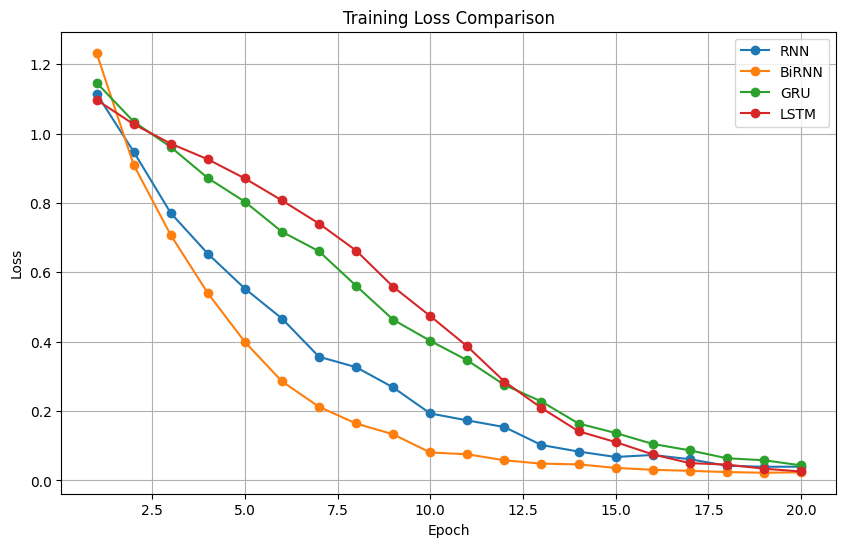

In [78]:
# ==========================================
# 57. TRAINING LOSS COMPARISON
# ==========================================

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

for name, history in histories.items():

    plt.plot(
        range(1, EPOCHS + 1),
        history["loss"],
        marker="o",
        label=name
    )

plt.title("Training Loss Comparison")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.show()

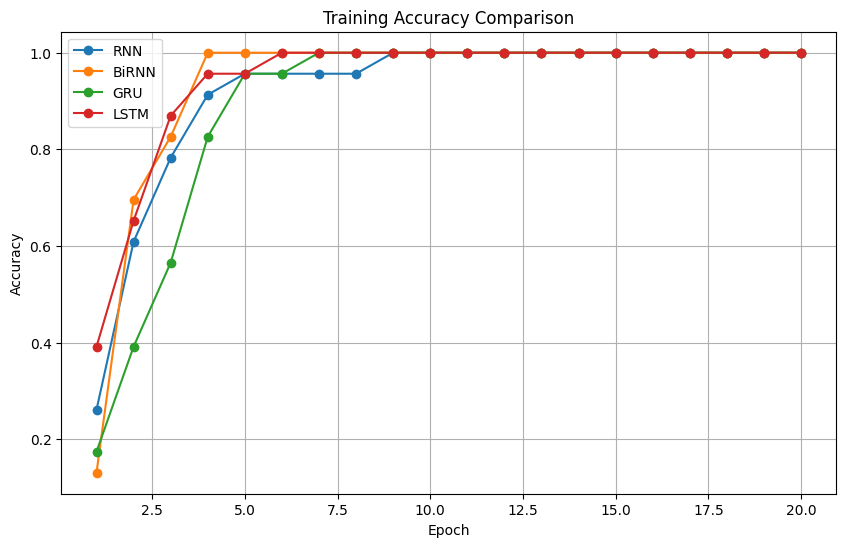

In [79]:
# ==========================================
# 58. TRAINING ACCURACY COMPARISON
# ==========================================

plt.figure(figsize=(10, 6))

for name, history in histories.items():

    plt.plot(
        range(1, EPOCHS + 1),
        history["accuracy"],
        marker="o",
        label=name
    )

plt.title("Training Accuracy Comparison")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.show()

In [80]:
# ==========================================
# 59. MODEL EVALUATION FUNCTION
# ==========================================

def predict_model(model, data_loader):

    model.eval()

    all_predictions = []
    all_labels = []

    with torch.no_grad():

        for batch_texts, batch_labels in data_loader:

            batch_texts = batch_texts.to(device)

            outputs = model(batch_texts)

            predictions = torch.argmax(
                outputs,
                dim=1
            )

            all_predictions.extend(
                predictions.cpu().numpy()
            )

            all_labels.extend(
                batch_labels.numpy()
            )

    return all_labels, all_predictions


print("Fonction de prédiction créée !")

Fonction de prédiction créée !


In [81]:
# ==========================================
# 60. EVALUATE ALL MODELS
# ==========================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

results = {}

for name, model in models.items():

    y_true, y_pred = predict_model(
        model,
        test_loader
    )

    results[name] = {
        "Accuracy": accuracy_score(y_true, y_pred),

        "Precision": precision_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "Recall": recall_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "F1-score": f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        )
    }

    print("\n" + "=" * 50)
    print("RESULTATS DU MODELE :", name)
    print("=" * 50)

    print(
        classification_report(
            y_true,
            y_pred,
            labels=[0, 1, 2],
            target_names=[
                "Classe 0",
                "Classe 1",
                "Classe 2"
            ],
            zero_division=0
        )
    )

print("Évaluation terminée !")


RESULTATS DU MODELE : RNN
              precision    recall  f1-score   support

    Classe 0       0.40      0.67      0.50         3
    Classe 1       0.40      0.67      0.50         3
    Classe 2       1.00      0.20      0.33         5

    accuracy                           0.45        11
   macro avg       0.60      0.51      0.44        11
weighted avg       0.67      0.45      0.42        11


RESULTATS DU MODELE : BiRNN
              precision    recall  f1-score   support

    Classe 0       0.00      0.00      0.00         3
    Classe 1       0.67      0.67      0.67         3
    Classe 2       0.40      0.40      0.40         5

    accuracy                           0.36        11
   macro avg       0.36      0.36      0.36        11
weighted avg       0.36      0.36      0.36        11


RESULTATS DU MODELE : GRU
              precision    recall  f1-score   support

    Classe 0       0.33      0.33      0.33         3
    Classe 1       1.00      0.67      0.80   

In [82]:
# ==========================================
# 61. MODEL COMPARISON TABLE
# ==========================================

results_df = pd.DataFrame(results).T

display(
    results_df.round(4)
)

,Accuracy,Precision,Recall,F1-score
RNN,0.4545,0.6000,0.5111,0.4444
BiRNN,0.3636,0.3556,0.3556,0.3556
GRU,0.6364,0.6667,0.6000,0.6202
LSTM,0.8182,0.8667,0.8222,0.8130


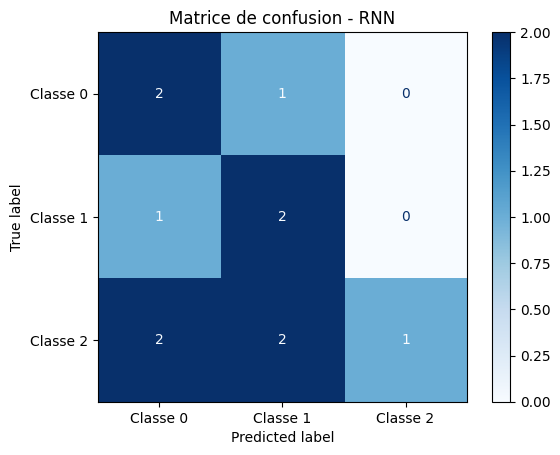

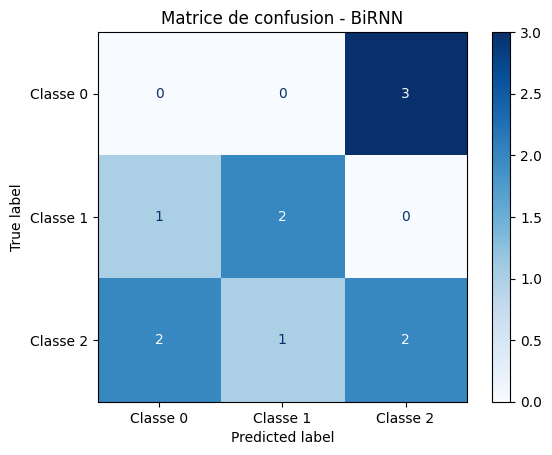

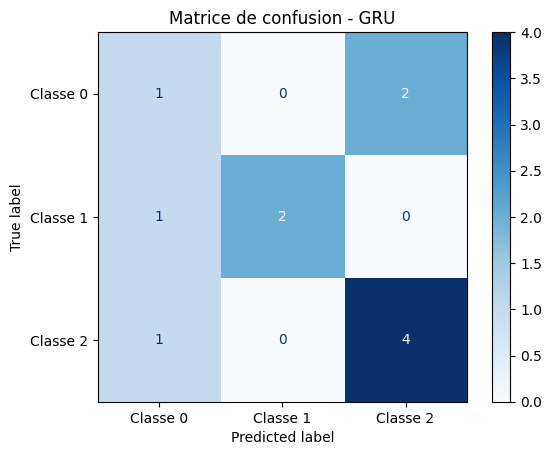

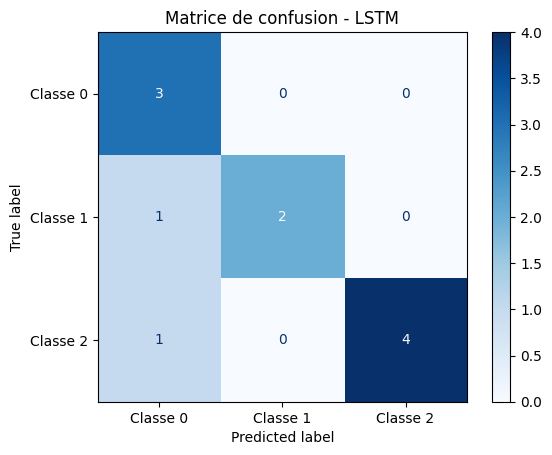

In [83]:
# ==========================================
# 62. CONFUSION MATRICES
# ==========================================

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

for name, model in models.items():

    y_true, y_pred = predict_model(
        model,
        test_loader
    )

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1, 2]
    )

    display_matrix = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=[
            "Classe 0",
            "Classe 1",
            "Classe 2"
        ]
    )

    display_matrix.plot(cmap="Blues")

    plt.title(f"Matrice de confusion - {name}")
    plt.show()

In [84]:
# ==========================================
# 63. IDENTIFY BEST MODEL
# ==========================================

best_model_name = results_df["F1-score"].idxmax()

best_f1 = results_df.loc[
    best_model_name,
    "F1-score"
]

print("Meilleur modèle selon le Macro F1-score :")
print(best_model_name)

print("\nMacro F1-score :", round(best_f1, 4))

Meilleur modèle selon le Macro F1-score :
LSTM

Macro F1-score : 0.813


In [85]:
# ==========================================
# 65. SAVE TRAINED MODELS AND RESULTS
# ==========================================

import os

os.makedirs(
    "/kaggle/working/models",
    exist_ok=True
)

# Sauvegarder chaque modèle
for name, model in models.items():

    torch.save(
        model.state_dict(),
        f"/kaggle/working/models/{name}.pth"
    )

# Sauvegarder les résultats
results_df.to_csv(
    "/kaggle/working/model_comparison.csv",
    encoding="utf-8-sig"
)

print("Modèles et résultats sauvegardés !")

Modèles et résultats sauvegardés !


In [86]:
# ==========================================
# 67. TEXT CLASSIFICATION FUNCTION
# ==========================================

def predict_article(text):

    # 1. Normalisation
    normalized = normalize_arabic(text)

    # 2. Tokenisation
    tokens = simple_word_tokenize(normalized)

    # 3. Suppression des Stop Words
    tokens = [
        word for word in tokens
        if word not in arabic_stopwords
    ]

    # 4. Stemming
    tokens = [
        stemmer.stem(word)
        for word in tokens
    ]

    # 5. Encodage
    encoded = encode_text(tokens, word2idx)

    # 6. Padding
    padded = pad_sequences([encoded], MAX_LEN)

    # 7. Conversion en tenseur
    input_tensor = torch.tensor(
        padded,
        dtype=torch.long
    ).to(device)

    # 8. Prédiction
    best_model = models["LSTM"]
    best_model.eval()

    with torch.no_grad():

        outputs = best_model(input_tensor)

        probabilities = torch.softmax(
            outputs,
            dim=1
        )

        predicted_class = torch.argmax(
            probabilities,
            dim=1
        ).item()

    # 9. Résultat
    class_names = {
        0: "Non directement liée à la technologie",
        1: "Liée au numérique et à la technologie",
        2: "Directement liée à l'intelligence artificielle"
    }

    confidence = probabilities[0][predicted_class].item()

    return {
        "Texte": text,
        "Classe prédite": predicted_class,
        "Catégorie": class_names[predicted_class],
        "Score du modèle": round(confidence * 100, 2)
    }


print("Fonction de classification créée !")

Fonction de classification créée !


In [88]:
# ==========================================
# 68. TEST NEW ARABIC ARTICLES
# ==========================================

test_articles = [

    "ارتفاع أسعار النفط في الأسواق العالمية",

    "تعتمد المؤسسات على الأنظمة الرقمية لتحسين العمل",

    "الذكاء الاصطناعي يساعد في تشخيص الأمراض",

    "تطور الروبوتات الذكية في المصانع",

    "انطلاق بطولة كرة القدم هذا الأسبوع"

]

for article in test_articles:

    result = predict_article(article)

    print("\nTexte :", result["Texte"])
    print("Classe :", result["Classe prédite"])
    print("Catégorie :", result["Catégorie"])
    print("Confiance du modèle :", result["Score du modèle"], "%")
    print("-" * 60)


Texte : ارتفاع أسعار النفط في الأسواق العالمية
Classe : 1
Catégorie : Liée au numérique et à la technologie
Confiance du modèle : 74.27 %
------------------------------------------------------------

Texte : تعتمد المؤسسات على الأنظمة الرقمية لتحسين العمل
Classe : 1
Catégorie : Liée au numérique et à la technologie
Confiance du modèle : 73.13 %
------------------------------------------------------------

Texte : الذكاء الاصطناعي يساعد في تشخيص الأمراض
Classe : 2
Catégorie : Directement liée à l'intelligence artificielle
Confiance du modèle : 68.95 %
------------------------------------------------------------

Texte : تطور الروبوتات الذكية في المصانع
Classe : 2
Catégorie : Directement liée à l'intelligence artificielle
Confiance du modèle : 52.39 %
------------------------------------------------------------

Texte : انطلاق بطولة كرة القدم هذا الأسبوع
Classe : 1
Catégorie : Liée au numérique et à la technologie
Confiance du modèle : 48.62 %
-------------------------------------------

In [89]:
# ==========================================
# 69. SAVE LSTM CONFIGURATION
# ==========================================

import json

# Sauvegarder le vocabulaire
with open(
    "/kaggle/working/word2idx.json",
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        word2idx,
        file,
        ensure_ascii=False,
        indent=4
    )

# Sauvegarder les paramètres
config = {
    "model_type": "LSTM",
    "vocab_size": vocab_size,
    "embedding_dim": EMBEDDING_DIM,
    "hidden_dim": HIDDEN_DIM,
    "num_classes": NUM_CLASSES,
    "num_layers": NUM_LAYERS,
    "dropout": DROPOUT,
    "max_len": MAX_LEN
}

with open(
    "/kaggle/working/lstm_config.json",
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        config,
        file,
        indent=4
    )

print("Configuration et vocabulaire sauvegardés !")

Configuration et vocabulaire sauvegardés !


In [94]:
!pip install -q transformers==4.46.3 tokenizers==0.20.3 datasets==3.1.0 accelerate==1.1.1

In [95]:
import pandas as pd
import numpy as np
import torch
import os
import random

from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
    Trainer,
    TrainingArguments,
    DataCollatorForLanguageModeling
)

print("PyTorch :", torch.__version__)
print("CUDA disponible :", torch.cuda.is_available())

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Appareil utilisé :", device)

PyTorch : 2.11.0+cu130
CUDA disponible : True
Appareil utilisé : cuda


In [96]:
raw_df = pd.read_csv(
    "/kaggle/working/arabic_dataset_extended.csv"
)

print("Dataset chargé :", raw_df.shape)

Dataset chargé : (34, 12)


In [97]:
print("Valeurs manquantes :")
print(raw_df[["Title", "Text"]].isnull().sum())

print("\nNombre de textes vides :")
print(
    (raw_df["Text"].fillna("").str.strip() == "").sum()
)

Valeurs manquantes :
Title    0
Text     0
dtype: int64

Nombre de textes vides :
0


In [98]:
generation_df = raw_df[["Title", "Text"]].copy()

generation_df = generation_df.dropna(
    subset=["Title", "Text"]
)

generation_df["Title"] = generation_df["Title"].astype(str).str.strip()
generation_df["Text"] = generation_df["Text"].astype(str).str.strip()

generation_df = generation_df[
    (generation_df["Title"] != "") &
    (generation_df["Text"] != "")
]

generation_df = generation_df.drop_duplicates(
    subset=["Title", "Text"]
).reset_index(drop=True)

print("Nombre de textes pour GPT-2 :", len(generation_df))

display(generation_df.head())

Nombre de textes pour GPT-2 : 34


,Title,Text
0,الذكاء الاصطناعي باللغة العربية.. هل اقتربنا م...,وقت القراءة: 6 دقائق الذكاء الاصطناعي باللغة ا...
1,هل يجعلنا الذكاء الاصطناعي أغبى؟,وقت القراءة: 11 دقيقة استمع تستطيع أدوات الذكا...
2,الذكاء الاصطناعي: هل تهدّد هذه التكنولوجيا مست...,صدر الصورة، Getty Images ربما قرأت في السنوات ...
3,مواد جديدة يصممها الذكاء الاصطناعي قد تغير مست...,BBC 16 نوفمبر 2026 بقلم BBC News عربي مواد جدي...
4,ارتفاع أسعار الخضروات في الأسواق,شهدت الأسواق ارتفاعا في أسعار الخضروات خلال ال...


In [99]:
generation_df["Full_Text"] = (
    "العنوان: " + generation_df["Title"] +
    "\nالمقال: " + generation_df["Text"]
)

texts = generation_df["Full_Text"].tolist()

print("Nombre de textes :", len(texts))

print("\nExemple de texte :")
print(texts[0])

Nombre de textes : 34

Exemple de texte :
العنوان: الذكاء الاصطناعي باللغة العربية.. هل اقتربنا من نماذج تفهم لهجات المنطقة؟
المقال: وقت القراءة: 6 دقائق الذكاء الاصطناعي باللغة العربية يشهد تطورا متسارعا مع ظهور نماذج متخصصة تهدف إلى فهم اللغة وسياقاتها الثقافية (الجزيرة) استمع كانت اللغة العربية في عالم الذكاء الاصطناعي تعتبر مجرد لغة تُترجم إليها الإجابات أو تُدعم في واجهات الاستخدام، لكن حاليا أصبحت محور سباق تقني متسارع تقوده شركات عالمية ومؤسسات بحثية عربية لتطوير نماذج لغوية قادرة على فهم خصوصية العربية ولهجاتها المتعددة. وخلال العامين الأخيرين، انتقل التركيز من دعم العربية الفصحى إلى معالجة تحدٍ أكثر تعقيدا، يتمثل في فهم اللهجات المحلية التي يستخدمها مئات الملايين يوميا، بدءا من اللهجة السعودية والخليجية، مرورا بالمصرية والشامية، وصولا إلى المغربية التي تختلف مفرداتها وتراكيبها بشكل كبير عن الفصحى. يعد تطوير نماذج لغوية للعربية أكثر تعقيدا مقارنة بلغات أخرى، فالعربية ليست لغة واحدة من الناحية العملية، وإنما منظومة تضم اللغة العربية الفصحى وعشرات اللهجات الإقليمية والمحلية، التي

In [100]:
lengths = [len(text.split()) for text in texts]

print("Nombre moyen de mots :", np.mean(lengths))
print("Nombre minimum de mots :", np.min(lengths))
print("Nombre maximum de mots :", np.max(lengths))

Nombre moyen de mots : 118.0
Nombre minimum de mots : 22
Nombre maximum de mots : 1356


In [101]:
MODEL_NAME = "aubmindlab/aragpt2-base"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

print("Tokenizer chargé avec succès")
print("Taille du vocabulaire :", len(tokenizer))

config.json:   0%|          | 0.00/843 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Tokenizer chargé avec succès
Taille du vocabulaire : 64000


In [102]:
model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME
)

model.to(device)

print("GPT-2 chargé avec succès")

model.safetensors:   0%|          | 0.00/553M [00:00<?, ?B/s]

GPT-2 chargé avec succès


In [103]:
MAX_LENGTH = 256

print("Longueur maximale :", MAX_LENGTH)

Longueur maximale : 256


In [107]:
# Configurer le token de padding
tokenizer.pad_token = tokenizer.eos_token

# Configurer également le modèle
model.config.pad_token_id = tokenizer.pad_token_id

# Tokenisation du dataset
tokenized_data = tokenizer(
    texts,
    truncation=True,
    max_length=MAX_LENGTH,
    padding="max_length",
    return_attention_mask=True
)

print("Tokenisation terminée avec succès !")

print("Nombre d'exemples :", len(tokenized_data["input_ids"]))

print(
    "Nombre de tokens du premier texte :",
    len(tokenized_data["input_ids"][0])
)

print("PAD Token :", tokenizer.pad_token)
print("PAD Token ID :", tokenizer.pad_token_id)

Tokenisation terminée avec succès !
Nombre d'exemples : 34
Nombre de tokens du premier texte : 256
PAD Token : <|endoftext|>
PAD Token ID : 0


In [109]:
class ArabicGenerationDataset(torch.utils.data.Dataset):

    def __init__(self, encodings):
        self.encodings = encodings

    def __len__(self):
        return len(self.encodings["input_ids"])

    def __getitem__(self, idx):

        item = {
            key: torch.tensor(value[idx])
            for key, value in self.encodings.items()
        }

        item["labels"] = item["input_ids"].clone()

        return item


train_dataset = ArabicGenerationDataset(tokenized_data)

print("Dataset PyTorch créé :", len(train_dataset))

Dataset PyTorch créé : 34


In [110]:
data_collator = DataCollatorForLanguageModeling(
    tokenizer=tokenizer,
    mlm=False
)

print("Data Collator configuré")

Data Collator configuré


In [111]:
training_args = TrainingArguments(
    output_dir="/kaggle/working/arabic_gpt2_results",

    num_train_epochs=10,

    per_device_train_batch_size=2,

    gradient_accumulation_steps=2,

    learning_rate=5e-5,

    weight_decay=0.01,

    logging_steps=1,

    save_strategy="epoch",

    report_to="none",

    fp16=torch.cuda.is_available(),

    seed=42
)

print("Paramètres d'entraînement configurés")

Paramètres d'entraînement configurés


In [112]:
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    data_collator=data_collator
)

print("Trainer créé avec succès")

Trainer créé avec succès


In [113]:
training_result = trainer.train()

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Step,Training Loss
1,9.691300
2,9.648900
3,9.709700
4,8.252600
5,8.705700
6,8.101800
7,7.330500
8,6.942300
9,7.098000
10,6.004100


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector

In [114]:
OUTPUT_DIR = "/kaggle/working/arabic_gpt2_finetuned"

trainer.save_model(OUTPUT_DIR)
tokenizer.save_pretrained(OUTPUT_DIR)

print("Modèle sauvegardé dans :", OUTPUT_DIR)

Modèle sauvegardé dans : /kaggle/working/arabic_gpt2_finetuned


In [115]:
def generate_paragraph(prompt, max_new_tokens=100):

    model.eval()

    inputs = tokenizer(
        prompt,
        return_tensors="pt"
    ).to(device)

    with torch.no_grad():

        outputs = model.generate(
            **inputs,

            max_new_tokens=max_new_tokens,

            do_sample=True,

            temperature=0.8,

            top_k=50,

            top_p=0.95,

            repetition_penalty=1.2,

            pad_token_id=tokenizer.eos_token_id
        )

    generated_text = tokenizer.decode(
        outputs[0],
        skip_special_tokens=True
    )

    return generated_text

In [116]:
prompt = "الذكاء الاصطناعي أصبح من أهم التقنيات الحديثة"

generated_text = generate_paragraph(
    prompt,
    max_new_tokens=100
)

print("Phrase de départ :")
print(prompt)

print("\nTexte généré :")
print(generated_text)

Phrase de départ :
الذكاء الاصطناعي أصبح من أهم التقنيات الحديثة

Texte généré :
الذكاء الاصطناعي أصبح من أهم التقنيات الحديثة في إدارة البيانات ، وتطوير الذكاء الاصطناعي وتحسين الخدمات عبر الإنترنت وتخزين المعلومات ومعالجتها .المقال: تطوير أنظمة ذكاء اصطناعي للاتصال باستخدام شبكة إنترنت ذكية لتسهيل تبادل الوثائق وتبادل المعلومات بين الأجهزة الإلكترونية. تستخدم التكنولوجيا الرقمية للتحكم بسرعة المعلومات وتعزيز كفاءة الموظفين وتسهيل الإجراءات الإدارية. تساعد هذه الأنظمة على تحسين إنتاجية العمل والإنتاجية وتحسين الإنتاجية وتقليل تكاليف الإنفاق. طورت شركة أمازون نظاما ذكيا يقوم بتغيير إعدادات المستخدمين وتسهيل المهام اليومية. تعتمد شركات الحوسبة السحابية على استخدام تقنيات الذكاء الاصطناعي لتطوير البرمجيات الآلية لتسريع مهام الموظفين. يستخدم الباحثون أنظمة الذكاء الاصطناعي لمساعدة
